# Neural-Network Manhours Model — Crew-Day Batching

## 1 — Setup

### 1a. Imports and the shared function module

In [1]:
import copy
import os
import sys
import time
import importlib

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from sklearn.preprocessing import OneHotEncoder, MinMaxScaler
from torch import nn
from torch.utils.data import DataLoader, TensorDataset
from sklearn.metrics import r2_score

# Where the shared module lives. Adjust MODULE_DIR if your folder layout differs.
NOTEBOOK_DIR = "/mnt/projects/VEG_Contractors/2026unitization/2026unitization/notebooks"
MODULE_DIR = os.environ.get("VEG_MODULE_DIR",
                            os.path.join(os.path.abspath(os.path.join(NOTEBOOK_DIR, os.pardir)), "src", "modeling"))
for path in (MODULE_DIR, NOTEBOOK_DIR):
    if path not in sys.path:
        sys.path.insert(0, path)

# Prefer the bundled module (shipped next to this notebook); fall back to the updated copy in src/modeling.
for module_name in ("veg_pipeline_functions_v2", "veg_pipeline_updated"):
    try:
        vp = importlib.import_module(module_name)
        print(f"Shared functions loaded from: {vp.__file__}")
        break
    except ModuleNotFoundError:
        continue
else:
    raise ModuleNotFoundError(f"Could not find veg_pipeline_updated.py / veg_pipeline_functions_v2.py in {MODULE_DIR}")

Shared functions loaded from: /mnt/projects/VEG_Contractors/2026unitization/2026unitization/src/modeling/veg_pipeline_functions_v2.py


/usr/local/lib/python3.10/dist-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


### 1b. Configuration
Everything you might change lives here.

In [2]:
# ---- Phase switch --------------------------------------------------------------------------
READY_FOR_FINAL_HOLDOUT = False   # <-- BREAKPOINT: True only for the one-time final holdout run
RUN_MODE = os.environ.get("VEG_RUN_MODE", "full")   # "full" | "fast" (quick smoke test)
FAST = RUN_MODE == "fast"
SHOW_PLOTS = True                 # figures are always saved to FIG_DIR too

# ---- Paths ---------------------------------------------------------------------------------
OUTPUT_DIR = os.environ.get("VEG_OUTPUT_DIR", "../deployment")
INPUT_DIR = os.environ.get("VEG_INPUT_DIR", "../../input_data")
FULL_SPLIT_DIR = os.path.join(OUTPUT_DIR, "splits", "full_features")   # written by the CatBoost pipeline
DECISIONS_PATH = os.path.join(OUTPUT_DIR, "final_decisions.json")      # tiers, area column, sample weights
NN_DIR = os.path.join(OUTPUT_DIR, "nn")
FIG_DIR = os.path.join(NN_DIR, "figures")
TB_DIR = os.path.join(NN_DIR, "tensorboard")                          # TensorBoard event files
os.makedirs(FIG_DIR, exist_ok=True)
os.makedirs(TB_DIR, exist_ok=True)

# ---- Protective devices ----------------------------------------------------------------------
DEVICE_SOURCE = os.path.join(INPUT_DIR, "span_data.pkl")   # needs a bay column + device columns
DEVICE_BAY_COL = "bay"
PROTECTIVE_DEVICE_COLS = ["protective_device", "major_protective_device"]

# ---- TensorBoard -----------------------------------------------------------------------------
USE_TENSORBOARD = True
TB_PORT = 6006                    # first port to try; the next 10 are tried if it is busy
TB_HOST = "0.0.0.0"               # listen on all container interfaces so podman / VS Code forwarding can reach it
TB_EMBED = True                   # also try to show the dashboard inside the notebook (needs the port forwarded)
TB_LOG_TRIALS = True              # one TensorBoard run per tuning trial (useful, but many runs)

# ---- Network / training settings -------------------------------------------------------------
NN_CFG = {
    "n_trials": 3 if FAST else 30,          # hyperparameter search size
    "max_epochs": 15 if FAST else 300,      # hard cap; early stopping usually ends sooner
    "patience": 4 if FAST else 25,          # epochs without improvement before stopping
    "es_feeder_share": 0.15,                # share of fitting feeders held out for early stopping
    "n_seeds_final": 1 if FAST else 5,      # models averaged for the final predictions
    "min_category_count": 20,               # rarer categories are treated as "unknown"
    "skew_log_threshold": 2.0,              # log-transform numeric columns this skewed
    "clip_z": 6.0,                          # clip standardized values to +/- this
    "w_span_mae": 0.5,                      # selection score = 0.5 * span MAE + 0.5 * feeder WAPE
    "w_feeder_wape": 0.5,                   #   (each relative to a naive predictor)
    "quantile_alphas": (0.10, 0.90),        # P10 / P90 heads
    "quantile_loss_weight": 0.5,            # weight of the P10/P90 terms vs the point loss
    "use_chosen_area_only": True,           # drop the three area columns the pipeline rejected
    "weight_scheme": "primary",             # tier weights: "primary" | "hours" | "volume" | None
    "run_group_permutation": True,
    "tune": "auto",                         # True | False | "auto" (re-tune only if inputs changed)
    "train_mae_sample": 5000,               # rows used to track training error each epoch
}
LOSS_CHOICES = ["l1", "smooth_l1"]          # l1 == MAE; smooth_l1 is the Huber-style alternative
ARCH_CHOICES = ["shared_two_head", "split"] # one network with 2 heads, or 2 separate networks
DEFAULT_SPEC = {"arch": "shared_two_head", "loss": "l1", "width": 256, "n_blocks": 3, "dropout": 0.15,
                "emb_dropout": 0.05, "lr": 1e-3, "weight_decay": 1e-4, "batch_size": 512, "weight_strength": 0.0}

# ---- Crew-day batching ------------------------------------------------------------------------
SPAN_ID_COL = "bay_unique"                # join key between span_data and the split files
FEEDER_COL = "feeder"
CREW_LEADER_COL = "crew_leader"
COMPLETE_DATE_COL = "complete_date"
CREW_DAY_COL = "crew_day_id"
# Spans with a missing crew leader or completion date (or not found in span_data) have no known crew-day.
DROP_UNKNOWN_CREWDAY_TRAIN = True         # True: leave them out of fitting and early stopping entirely
DROP_UNKNOWN_CREWDAY_EVAL = False         # True: also leave them out of Validation / holdout scoring.
                                          #   Keep False to score every span, as pricing will have to.
# ---- Re-split by crew-day (replaces the feeder-based splits from the CatBoost pipeline) -----------------
HOLDOUT_MIN_SHARE = 0.15                  # holdout grows 1 month at a time (most recent first) until it holds
HOLDOUT_MAX_MONTHS = 6                    #   at least this share of dated spans, up to this many months
HOLDOUT_WARN_MAX_SHARE = 0.35             # warn if the recent window swallows more than this share of the data
NONHOLDOUT_SHARES = {"train": 0.70, "valid": 0.15, "test": 0.15}   # of the earlier crew-days, drawn at random
ES_SHARE = 0.25                           # change: share of Train spans (whole split groups) used only for
                                          #   early stopping (v11: ES_CREWDAY_SHARE = 0.15 of random crew-days)
SPLIT_STRATEGY = "auto"                   #  change: "auto" | "component" | "feeder" | "crew_day" (v11 behaviour)
MAX_COMPONENT_SHARE = 0.35                #  change: auto uses feeder groups linked by crew-days unless the
                                          #   largest group holds more than this share of spans, then plain feeders
CREWDAY_SPLIT_DIR = os.path.join(NN_DIR, "splits_crewday")          # the new splits are saved here
CREW_DAYS_PER_BATCH = 128                 # whole crew-days per step (v9: 32 - too noisy); a crew-day is never split
CREWDAY_LOSS_NORM = "none"                # "none": error on crew-day totals | "per_span": total error / n spans
SPAN_AUX_WEIGHT = 0.1                     # small per-span term anchoring individual spans (v9: 0.0).
                                          #   Set back to 0.0 if Step 3e shows most days have identical span hours
SHARE_LOSS_WEIGHT = 0.5                   # "crew_day_share" mode: weight of the within-day share term
# change: runs are (mode, loss) pairs (v11: TRAINING_MODES, L1 only). Identical network, data and seeds.
#   modes: "crew_day"       - loss on crew-day totals only
#          "crew_day_share" - crew-day totals + each span's share of its day's hours (teaches the within-day split)
#          "span"           - ordinary per-span loss (baseline)
#   losses: "l1" (targets the typical span) | "poisson" (targets the average; count-like hours) | "smooth_l1"
TRAINING_RUNS = [
    {"mode": "crew_day", "loss": "l1"},
    {"mode": "crew_day_share", "loss": "l1"},
    {"mode": "span", "loss": "l1"},
    {"mode": "crew_day", "loss": "poisson"},
]

# ---- Regularised setup (v10) -----------------------------------------------------------------------
# v9 overfit (fit vs early-stop gap widening every epoch) and was jumpy. Smaller network, more dropout and
# weight decay, a lower learning rate and bigger batches (CREW_DAYS_PER_BATCH above) address both.
# v9 values: width 256, n_blocks 3, dropout 0.15, emb_dropout 0.05, lr 1e-3, weight_decay 1e-4.
DEFAULT_SPEC.update({"width": 128, "n_blocks": 2, "dropout": 0.30, "emb_dropout": 0.10,
                     "lr": 3e-4, "weight_decay": 1e-3})
FEATURE_COLS = None                       #  all FULL_X columns, L1 penalty selects (v10/v11: "rfe");
                                          #   "rfe" -> the CatBoost RFE subset;
                                          #   or an explicit list of column names
RFE_FEATURES_FILE = None                  # optional .json list or .txt (one name per line) holding rfe_best_features
RFE_MODEL_FILE = "catboost_road_nonveg_rfe.cbm"   # else the feature names are read from this saved CatBoost model
WORKLOAD_COL = "bay_l&r_blue_(ft)"              # span workload measure for the within-day check (Step 3f)
APPLY_SCALE_FACTOR = True                 # rescale each run so early-stop totals match (L1's low bias)
HIGH_CARDINALITY_WARN = 100               # flag categorical inputs with more categories than this (memorisation risk)

# ---- stability, feature selection and unit-level evaluation ------------------------------
DEVICE_COL = "protective_device"          # protective device ID column (FULL_META or FULL_X); None to skip
W_DEVICE_WAPE = 0.0                       # weight of device WAPE in the score (span / feeder weights in NN_CFG)
L1_INPUT_PENALTY = 1e-4                   # L1 on first-layer weights: pushes unhelpful inputs toward zero; 0 = off
INACTIVE_INPUT_SHARE = 0.05               # inputs below this share of the strongest count as switched off (5e)
WARMUP_EPOCHS = 5                         # learning rate ramps from 10% to full over these epochs; 0 = off
EMA_DECAY = 0.98                          # weight averaging per step; None = off (~1 epoch of steps averaged)
ES_SMOOTH_EPOCHS = 3                      # early stopping / LR cuts follow the average score of this many epochs
SCORE_ON_SCALED = True                    # score each epoch after rescaling to early-stop totals (as used later)
N_SEEDS = 3                               # seeds per run, predictions averaged (1 in FAST mode)
UNIT_BAND = (0.10, 0.90)                  # error band percentiles for device / feeder totals (Step 6b)
DROP_FEATURES = ["area_lc","area_xfmr"]                        # extra columns to exclude (e.g. the area columns the pipeline rejected)
ANALYSIS_ONLY_COLS = ["veg_tier", "total_veg_work"]   # never model inputs; add the trim/removal count columns here

print(f"RUN_MODE={RUN_MODE} | READY_FOR_FINAL_HOLDOUT={READY_FOR_FINAL_HOLDOUT}")
pd.Series(NN_CFG)

RUN_MODE=full | READY_FOR_FINAL_HOLDOUT=False


n_trials                         30
max_epochs                      300
patience                         25
es_feeder_share                0.15
n_seeds_final                     5
min_category_count               20
skew_log_threshold              2.0
clip_z                          6.0
w_span_mae                      0.5
w_feeder_wape                   0.5
quantile_alphas          (0.1, 0.9)
quantile_loss_weight            0.5
use_chosen_area_only           True
weight_scheme               primary
run_group_permutation          True
tune                           auto
train_mae_sample               5000
dtype: object

### 1c. Reproducibility and hardware

In [3]:
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
SEED = vp.RANDOM_STATE


def set_seed(seed):
    """Same seed -> same shuffling, dropout masks and initial weights."""
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


def fig_path(name):
    return os.path.join(FIG_DIR, name)


set_seed(SEED)
print(f"Device: {DEVICE} | torch {torch.__version__} | seed {SEED}")

Device: cpu | torch 2.1.2 | seed 42


## 2 — TensorBoard
Every training run writes its curves to its own sub-folder of `TB_DIR`. The cell below starts a TensorBoard server
as a separate process, **waits until it actually answers**, and shows a link (plus an embedded frame).

In [4]:
SummaryWriter = None
if USE_TENSORBOARD:
    try:
        from torch.utils.tensorboard import SummaryWriter
        import tensorboard  # noqa: F401  -- the server package, separate from torch's writer
    except ImportError:
        print("tensorboard is not installed (pip install tensorboard) - curves will be shown with matplotlib only.")
        USE_TENSORBOARD = False

import signal
import socket
import subprocess
import urllib.request

TB_URL = None
TB_LOG = os.path.join(NN_DIR, "tensorboard_server.log")
TB_PID_FILE = os.path.join(NN_DIR, "tensorboard_server.pid")
TB_LAUNCHER = os.path.join(NN_DIR, "tb_launch.py")

# Built-in plugins only: skips third-party entry-point plugins such as open3d's, which crashes on import here.
_LAUNCHER_SRC = """\
import sys
from tensorboard import default, program

logdir, port, host = sys.argv[1], sys.argv[2], sys.argv[3]
tb = program.TensorBoard(plugins=default.get_static_plugins())
tb.configure(argv=[None, "--logdir", logdir, "--port", port, "--host", host, "--reload_interval", "15"])
sys.exit(tb.main())
"""
with open(TB_LAUNCHER, "w") as fh:
    fh.write(_LAUNCHER_SRC)

# Health checks go straight to the container's loopback. Corporate images often set http_proxy, which would
# otherwise route "localhost" through the proxy and make a healthy server look dead.
_NO_PROXY_OPENER = urllib.request.build_opener(urllib.request.ProxyHandler({}))


def _port_is_free(port):
    with socket.socket(socket.AF_INET, socket.SOCK_STREAM) as s:
        try:
            s.bind(("0.0.0.0", port))
            return True
        except OSError:
            return False


def stop_tensorboard():
    """Stop the server this notebook started (it deliberately survives kernel restarts)."""
    if not os.path.exists(TB_PID_FILE):
        return
    try:
        with open(TB_PID_FILE) as fh:
            os.kill(int(fh.read().strip()), signal.SIGTERM)
        time.sleep(1.0)
    except (ValueError, ProcessLookupError, PermissionError):
        pass
    os.remove(TB_PID_FILE)


def launch_tensorboard(logdir, first_port, host, timeout_s=60):
    """Start TensorBoard in its own process and return (port, pid) only once it answers HTTP requests."""
    stop_tensorboard()
    port = next((p for p in range(first_port, first_port + 10) if _port_is_free(p)), None)
    if port is None:
        raise RuntimeError(f"Ports {first_port}-{first_port + 9} are all busy.")
    log_fh = open(TB_LOG, "w")
    # sys.executable = the kernel's own Python, so the server uses the same environment as this notebook.
    proc = subprocess.Popen([sys.executable, TB_LAUNCHER, logdir, str(port), host],
                            stdout=log_fh, stderr=subprocess.STDOUT, start_new_session=True)
    with open(TB_PID_FILE, "w") as fh:
        fh.write(str(proc.pid))
    probe_host = "127.0.0.1" if host in ("0.0.0.0", "localhost", "127.0.0.1") else host
    deadline = time.time() + timeout_s
    while time.time() < deadline:
        if proc.poll() is not None:
            log_fh.close()
            with open(TB_LOG) as fh:
                raise RuntimeError(f"TensorBoard exited during start-up. Log tail:\n{fh.read()[-3000:]}")
        try:
            _NO_PROXY_OPENER.open(f"http://{probe_host}:{port}/", timeout=2)
            return port, proc.pid
        except OSError:
            time.sleep(1.0)
    raise RuntimeError(f"TensorBoard did not answer on port {port} within {timeout_s}s - see {TB_LOG}")


if USE_TENSORBOARD:
    from IPython.display import HTML, IFrame, display
    TB_PORT_USED, TB_PID = launch_tensorboard(os.path.abspath(TB_DIR), TB_PORT, TB_HOST)
    TB_URL = f"http://localhost:{TB_PORT_USED}"
    print("=" * 72)
    print(f"TensorBoard is answering on port {TB_PORT_USED} (PID {TB_PID}), bound to {TB_HOST}")
    print(f"Log directory: {os.path.abspath(TB_DIR)}")
    print(f"Blank frame? VS Code > Ports panel > Forward a Port > {TB_PORT_USED}, then open {TB_URL}")
    display(HTML(f'<a href="{TB_URL}" target="_blank">Open TensorBoard ({TB_URL})</a>'))
    if TB_EMBED:
        display(IFrame(TB_URL, width="100%", height=800))


def make_writer(run_name):
    """One TensorBoard run per training run. Returns None when TensorBoard is off."""
    if not USE_TENSORBOARD:
        return None
    # flush_secs=10: the default (120 s) makes a live run look empty for the first two minutes.
    return SummaryWriter(log_dir=os.path.join(TB_DIR, run_name), flush_secs=10)

TensorBoard is answering on port 6006 (PID 472679), bound to 0.0.0.0
Log directory: /mnt/projects/VEG_Contractors/2026unitization/2026unitization/notebooks/deployment/nn/tensorboard
Blank frame? VS Code > Ports panel > Forward a Port > 6006, then open http://localhost:6006


## 3 — Load data and decisions

### 3a. Feature splits
These files were produced by the CatBoost pipeline (Section 7) and hold every feature for all four splits.
Feeders never appear in more than one split.

In [5]:
FULL_X, FULL_Y, FULL_META, MANIFEST = vp.load_full_splits(FULL_SPLIT_DIR)

split_overview = pd.DataFrame({
    s: {"spans": len(FULL_X[s]), "feeders": FULL_META[s]["feeder"].nunique(),
        "inaccessible_share": FULL_META[s]["inaccessible"].mean(),
        "mean_hours": FULL_Y[s].mean(), "median_hours": FULL_Y[s].median(), "p90_hours": FULL_Y[s].quantile(0.9)}
    for s in ["train", "valid", "test", "holdout"]}).T
vp.show(split_overview, "Split overview", 3)

# No feeder may appear in two splits (otherwise scores are optimistic).
for a, b in [("train", "valid"), ("train", "test"), ("train", "holdout"),
             ("valid", "test"), ("valid", "holdout"), ("test", "holdout")]:
    assert set(FULL_META[a]["feeder"]).isdisjoint(FULL_META[b]["feeder"]), f"feeder overlap {a}/{b}"
print("Feeder separation check passed.")


Split overview


,spans,feeders,inaccessible_share,mean_hours,median_hours,p90_hours
train,12337.0,249.0,0.457,4.267,3.0,8.0
valid,2182.0,54.0,0.480,3.856,3.0,8.0
test,4159.0,54.0,0.469,4.777,4.0,10.0
holdout,4671.0,73.0,0.376,3.862,3.0,8.0


Feeder separation check passed.


### 3b. Crew-day IDs
A crew-day is one `crew_leader` on one calendar `complete_date`. Two corrections versus the previous version:

- **Missing leader or date.** `groupby(..., dropna=False)` pools *every* span with a missing leader or date into a
  single fake crew-day (different crews, different days). Those spans are flagged `crew_day_known = False` and
  given a placeholder `solo|` ID. With `DROP_UNKNOWN_CREWDAY_TRAIN = True` they are removed from fitting and early
  stopping (Step 4a); `DROP_UNKNOWN_CREWDAY_EVAL` decides whether they are scored.
- **Row alignment.** `merge` against `span_data` (which has duplicate bay records) can add rows and resets the
  index, so `FULL_META` would stop lining up row-for-row with `FULL_X` / `FULL_Y`. A `.map` lookup keeps the row
  count and order fixed, and the cell asserts it.

These IDs are attached to the original (feeder-based) splits only so that 3c can pool and re-split them.

*Restart the kernel before running this if the old merge cell ran in this session.*

In [6]:
span_df = vp.load_span_data(INPUT_DIR)
missing_cols = [c for c in (SPAN_ID_COL, CREW_LEADER_COL, COMPLETE_DATE_COL) if c not in span_df.columns]
assert not missing_cols, f"span data is missing {missing_cols}"

crew_src = span_df[[SPAN_ID_COL, CREW_LEADER_COL, COMPLETE_DATE_COL]].copy()
# Calendar day only: spans finished at 09:00 and 15:00 by the same crew are the same crew-day.
crew_src["_date"] = pd.to_datetime(crew_src[COMPLETE_DATE_COL], errors="coerce").dt.normalize()
# Stray spaces / capitalisation in leader names would otherwise split one crew into several.
crew_src["_leader"] = crew_src[CREW_LEADER_COL].astype("string").str.strip().str.upper().replace("", pd.NA)
known = (crew_src["_leader"].notna() & crew_src["_date"].notna()).to_numpy()
crew_src[CREW_DAY_COL] = np.where(
    known,
    crew_src["_leader"].astype(str) + "|" + crew_src["_date"].dt.strftime("%Y-%m-%d").astype(str),
    "solo|" + crew_src[SPAN_ID_COL].astype(str))

dup = crew_src[SPAN_ID_COL].duplicated(keep=False)
n_conflict = int(crew_src[dup].groupby(SPAN_ID_COL)[CREW_DAY_COL].nunique().gt(1).sum())
print(f"span_data rows: {len(crew_src):,} | missing leader or date: {(~known).sum():,} "
      f"| duplicated {SPAN_ID_COL} rows: {int(dup.sum())} (with conflicting crew-days: {n_conflict})")


def as_id_text(values):
    """Span IDs as trimmed text, so 1234, 1234.0 and "1234" all match between files."""
    v = pd.Series(values)
    if pd.api.types.is_float_dtype(v) and np.all(np.isclose(v.dropna() % 1, 0)):
        v = v.astype("Int64")
    return v.astype("string").str.strip()


crew_src[SPAN_ID_COL] = as_id_text(crew_src[SPAN_ID_COL]).to_numpy()
crew_lookup = crew_src.drop_duplicates(SPAN_ID_COL, keep="first").set_index(SPAN_ID_COL)[CREW_DAY_COL]
# Completion day on its own (also known when the leader is missing) - drives the time-based holdout in 3c.
date_lookup = crew_src.drop_duplicates(SPAN_ID_COL, keep="first").set_index(SPAN_ID_COL)["_date"]


def span_ids_for(split):
    """Find the span ID for a split's rows. The split files don't always carry it as a FULL_META column: it may be
    the index, sit in FULL_X, or use a different name/capitalisation. Returns a Series aligned to FULL_META rows."""
    m, x = FULL_META[split], FULL_X[split]
    target = SPAN_ID_COL.lower()
    for frame, where in ((m, "FULL_META"), (x, "FULL_X")):
        match = [c for c in frame.columns if str(c).lower() == target]
        if match:
            return pd.Series(frame[match[0]].to_numpy(), index=m.index), f"{where}['{match[0]}']"
        if frame.index.name is not None and str(frame.index.name).lower() == target:
            return pd.Series(frame.index.to_numpy(), index=m.index), f"{where}.index"
    raise KeyError(
        f"No '{SPAN_ID_COL}' found for split '{split}'.\n"
        f"  FULL_META columns: {list(m.columns)} (index name: {m.index.name})\n"
        f"  FULL_X columns containing 'bay' or 'span': "
        f"{[c for c in x.columns if 'bay' in str(c).lower() or 'span' in str(c).lower()]}\n"
        f"Set SPAN_ID_COL to the matching name, or re-export the splits with the span ID kept in the meta file.")


for s in FULL_META:
    FULL_META[s] = FULL_META[s].drop(columns=[CREW_DAY_COL], errors="ignore")
    n_rows = len(FULL_META[s])
    ids, source = span_ids_for(s)
    FULL_META[s][SPAN_ID_COL] = as_id_text(ids).to_numpy()
    print(f"{s:>7}: span IDs taken from {source}")
    solo_ids = "solo|" + FULL_META[s][SPAN_ID_COL].astype(str)
    FULL_META[s][CREW_DAY_COL] = FULL_META[s][SPAN_ID_COL].map(crew_lookup).fillna(solo_ids)
    # False for a missing leader/date AND for spans absent from span_data - neither has a usable crew-day.
    FULL_META[s]["crew_day_known"] = ~FULL_META[s][CREW_DAY_COL].str.startswith("solo|")
    FULL_META[s]["work_date"] = pd.to_datetime(FULL_META[s][SPAN_ID_COL].map(date_lookup))
    assert len(FULL_META[s]) == n_rows == len(FULL_X[s]) == len(FULL_Y[s]), f"row alignment broken in {s}"
    match_rate = FULL_META[s][SPAN_ID_COL].isin(crew_lookup.index).mean()
    if match_rate < 0.5:
        print(f"  WARNING: only {match_rate:.0%} of {s} span IDs are found in span_data - check the ID format "
              f"(e.g. sample meta ID {FULL_META[s][SPAN_ID_COL].iloc[0]!r} vs span_data ID {crew_lookup.index[0]!r})")
print("FULL_META row alignment check passed.")

Duplicate bay records found: 36
Spans: 24,284 | unique completion days: 134
span_data rows: 24,284 | missing leader or date: 1,966 | duplicated bay_unique rows: 0 (with conflicting crew-days: 0)
  train: span IDs taken from FULL_META.index
  valid: span IDs taken from FULL_META.index
   test: span IDs taken from FULL_META.index
holdout: span IDs taken from FULL_META.index
FULL_META row alignment check passed.


### 3c. Re-split by crew-day, with a recent-months holdout
The CatBoost splits keep feeders apart, but a crew often works feeders from two splits on the same day, so crew-days
were cut in pieces. Here all four splits are pooled and re-split so that **every crew-day sits in exactly one split**:

1. **Holdout = the most recent months of work, as few as possible.** It starts with the last 1 month before the
   latest completion date and adds one earlier month at a time (2, 3, ...) only while it still holds less than
   `HOLDOUT_MIN_SHARE` of the dated spans, stopping at `HOLDOUT_MAX_MONTHS`. A crew-day has a single date, so it can never
   straddle the cut-off. Only dates and IDs are used here; holdout hours are not looked at.
2. **Train / Validation / Test = the earlier crew-days**, assigned at random by crew-day (`NONHOLDOUT_SHARES`).
3. **Spans with no completion date** can't be placed in time, so they are left out of every split (counted below).
   Spans with a date but no crew leader are kept as one-span crew-days.

What this changes downstream:
- `FULL_X`, `FULL_Y` and `FULL_META` are **replaced** by the new splits; every later step uses them. The original
  split each row came from is kept as `orig_split` in `FULL_META`.
- The same **feeder now appears in several splits**, so feeder metrics are computed on the part of each feeder that
  falls in a split. Scores may be somewhat more optimistic than under the feeder split, because the model has seen
  other spans of the same feeders (a plausible effect, not measured). The time-based holdout is the honest check:
  it asks the model to predict *later* work, as pricing will.
- These splits differ from the CatBoost champion's, so NN and CatBoost numbers are no longer directly comparable.
  Re-score CatBoost on the saved splits (`CREWDAY_SPLIT_DIR`) before comparing them.

In [7]:
import json

SPLITS = ["train", "valid", "test", "holdout"]
y_name = getattr(FULL_Y["train"], "name", None)
ALL_X = pd.concat([FULL_X[s].reset_index(drop=True) for s in SPLITS], ignore_index=True)
ALL_Y = pd.concat([pd.Series(np.asarray(FULL_Y[s], dtype=float)) for s in SPLITS], ignore_index=True).rename(y_name)
ALL_META = pd.concat([FULL_META[s].reset_index(drop=True).assign(orig_split=s) for s in SPLITS], ignore_index=True)
assert len(ALL_X) == len(ALL_Y) == len(ALL_META), "pooled rows are misaligned"
n_dup = int(ALL_META[SPAN_ID_COL].duplicated().sum())
if n_dup:
    print(f"WARNING: {n_dup} span IDs appear in more than one original split")

dated = ALL_META["work_date"].notna().to_numpy()
work_date = ALL_META["work_date"]
last_day = work_date[dated].max()
print(f"Pooled spans: {len(ALL_META):,} | dated: {dated.sum():,} | no completion date (left out): {(~dated).sum():,}")
print(f"Completion dates: {work_date[dated].min():%Y-%m-%d} to {last_day:%Y-%m-%d}")
monthly = work_date[dated].dt.to_period("M").value_counts().sort_index()
vp.show(monthly.rename("spans").to_frame().T, "Dated spans per month", 0)

# Holdout: most recent month first; add one earlier month at a time only while below HOLDOUT_MIN_SHARE
window_rows = []
for HOLDOUT_MONTHS in range(1, HOLDOUT_MAX_MONTHS + 1):
    HOLDOUT_CUTOFF = last_day - pd.DateOffset(months=HOLDOUT_MONTHS)
    is_hold = dated & (work_date > HOLDOUT_CUTOFF).to_numpy()
    hold_share = is_hold.sum() / dated.sum()
    window_rows.append({"months": HOLDOUT_MONTHS, "after": f"{HOLDOUT_CUTOFF:%Y-%m-%d}",
                        "spans": int(is_hold.sum()), "share": hold_share})
    if hold_share >= HOLDOUT_MIN_SHARE:
        break
else:
    print(f"WARNING: even {HOLDOUT_MONTHS} months hold only {hold_share:.1%} of dated spans (< {HOLDOUT_MIN_SHARE:.0%}).")
vp.show(pd.DataFrame(window_rows).set_index("months"), "Holdout windows tried (most recent first)", 3)
print(f"Holdout: last {HOLDOUT_MONTHS} months (completion date after {HOLDOUT_CUTOFF:%Y-%m-%d}) "
      f"= {is_hold.sum():,} spans ({hold_share:.1%} of dated spans)")
if hold_share > HOLDOUT_WARN_MAX_SHARE:
    print(f"WARNING: the holdout is {hold_share:.0%} of the data - check the monthly table before accepting this cut.")

# earlier spans -> train / valid / test by split group (feeder components by default)
# Build components across ALL dated spans, including those in the holdout.
# Every feeder and every crew-day in a component must have the same split owner.
dated_meta = ALL_META.loc[dated]
assert dated_meta[FEEDER_COL].notna().all(), "Dated spans have missing feeder IDs"
assert dated_meta[CREW_DAY_COL].notna().all(), "Dated spans have missing crew-day IDs"

def feeder_crewday_components(meta):
    codes, _ = pd.factorize(meta[FEEDER_COL], sort=False)
    parent = np.arange(codes.max() + 1)

    def find(i):
        while parent[i] != i:
            parent[i] = parent[parent[i]]
            i = parent[i]
        return i

    members = pd.DataFrame({
        "crew_day": meta[CREW_DAY_COL].to_numpy(),
        "feeder_code": codes,
    })
    for feeders in members.groupby("crew_day")["feeder_code"].unique():
        root = find(feeders[0])
        for feeder in feeders[1:]:
            parent[find(feeder)] = root

    return pd.Series([f"comp|{find(i)}" for i in codes], index=meta.index)

component = pd.Series(pd.NA, index=ALL_META.index, dtype="object")
component.loc[dated] = feeder_crewday_components(dated_meta)

# Recent spans remain the holdout. Older spans connected to them cannot go
# into another split without breaking feeder or crew-day separation.
holdout_components = set(component.loc[is_hold])
excluded = dated & ~is_hold & component.isin(holdout_components).to_numpy()
earlier = dated & ~is_hold & ~excluded
em = ALL_META.loc[earlier]

SPLIT_USED = "component"  # Do not fall back to "feeder".
group_of = component.loc[earlier]
comp_sizes = group_of.value_counts()
if comp_sizes.empty:
    raise ValueError("No earlier components remain after isolating the holdout")
LARGEST_COMPONENT_SHARE = float(comp_sizes.iloc[0] / len(em))
print(f"Excluded {excluded.sum():,} older spans connected to holdout; "
      f"{len(comp_sizes):,} earlier components remain; "
      f"largest holds {LARGEST_COMPONENT_SHARE:.1%} of remaining spans.")


def assign_groups(keys, shares, seed):
    """Shuffle groups, then fill train / valid / test to their share of spans (by each group's midpoint)."""
    sizes = keys.value_counts()
    order = np.random.default_rng(seed).permutation(sizes.index.to_numpy())
    sz = sizes.loc[order].to_numpy()
    mid = (np.cumsum(sz) - sz / 2) / sz.sum()
    b1, b2 = np.cumsum([shares["train"], shares["valid"]]) / sum(shares.values())
    return dict(zip(order, np.where(mid <= b1, "train", np.where(mid <= b2, "valid", "test"))))


group_split = assign_groups(group_of, NONHOLDOUT_SHARES, SEED)
new_split = np.full(len(ALL_META), "undated", dtype=object)
new_split[is_hold] = "holdout"
new_split[earlier] = group_of.map(group_split).to_numpy()
new_split[new_split == "test"] = "valid"
SPLITS = ["train", "valid", "holdout"]
ALL_META["split"] = new_split
ALL_META["split_group"] = pd.Series(pd.NA, index=ALL_META.index, dtype="object")
ALL_META.loc[earlier, "split_group"] = group_of.to_numpy()
ALL_META.loc[is_hold, "split_group"] = "holdout"
# Feeders the model can have trained on (worked before the cut-off) vs feeders new in the holdout
pre_feeders = set(ALL_META.loc[earlier, FEEDER_COL])
ALL_META["feeder_seen_before"] = ALL_META[FEEDER_COL].isin(pre_feeders)

# Replace the working splits
FULL_X, FULL_Y, FULL_META = {}, {}, {}
for s in SPLITS:
    pos = np.flatnonzero(new_split == s)
    FULL_X[s] = ALL_X.iloc[pos].reset_index(drop=True)
    FULL_Y[s] = ALL_Y.iloc[pos].reset_index(drop=True)
    FULL_META[s] = ALL_META.iloc[pos].reset_index(drop=True)

# Checks
EARLY = SPLITS[:-1]
for i, a in enumerate(SPLITS):
    for b in SPLITS[i + 1:]:
        for key in (FEEDER_COL, CREW_DAY_COL):
            overlap = set(FULL_META[a][key]) & set(FULL_META[b][key])
            assert not overlap, f"{key} in both {a} and {b}: {len(overlap)} IDs"

assert all(len(FULL_META[s]) > 0 for s in SPLITS), "A split is empty; inspect component sizes"
assert FULL_META["holdout"]["work_date"].min() > max(
    FULL_META[s]["work_date"].max() for s in EARLY
)
print("Checks passed: feeders and crew-days are disjoint across all four splits.")
cd_owner = pd.concat([FULL_META[s][[CREW_DAY_COL]].assign(split=s) for s in EARLY])
cut_cds = cd_owner.groupby(CREW_DAY_COL)["split"].nunique().gt(1)
print(f"Checks passed ({SPLIT_USED} split). Crew-days seen in pieces across train/valid: "
      f"{int(cut_cds.sum()):,} of {len(cut_cds):,}")

split_sets = {s: (set(FULL_META[s][FEEDER_COL]), set(FULL_META[s][CREW_DAY_COL])) for s in SPLITS}
overview = {}
for s in SPLITS:
    m = FULL_META[s]
    others_f = set().union(*(split_sets[o][0] for o in SPLITS if o != s))
    others_c = set().union(*(split_sets[o][1] for o in SPLITS if o != s))
    row = {"spans": len(m), "crew_days": m[CREW_DAY_COL].nunique(), "feeders": m[FEEDER_COL].nunique(),
           "split_groups": m["split_group"].nunique(),
           "feeders_also_elsewhere": len(split_sets[s][0] & others_f),
           "crew_days_also_elsewhere": len(split_sets[s][1] & others_c),
           "unknown_crew_day_share": (~m["crew_day_known"]).mean(),
           "first_date": f"{m['work_date'].min():%Y-%m-%d}", "last_date": f"{m['work_date'].max():%Y-%m-%d}"}
    if s == "holdout":   # holdout hours stay unseen until the final gate
        row["spans_on_feeders_seen_before"] = m["feeder_seen_before"].mean()
    else:
        row.update({"mean_hours": FULL_Y[s].mean(), "median_hours": FULL_Y[s].median(),
                    "p90_hours": FULL_Y[s].quantile(0.9)})
    overview[s] = row
vp.show(pd.DataFrame(overview).T, f"Splits ({SPLIT_USED})", 3)

os.makedirs(CREWDAY_SPLIT_DIR, exist_ok=True)
for s in SPLITS:
    FULL_X[s].to_pickle(os.path.join(CREWDAY_SPLIT_DIR, f"X_{s}.pkl"))
    FULL_Y[s].to_pickle(os.path.join(CREWDAY_SPLIT_DIR, f"y_{s}.pkl"))
    FULL_META[s].to_pickle(os.path.join(CREWDAY_SPLIT_DIR, f"meta_{s}.pkl"))
with open(os.path.join(CREWDAY_SPLIT_DIR, "manifest.json"), "w") as fh:
    json.dump({"created": time.strftime("%Y-%m-%d %H:%M:%S"), "seed": SEED,
               "split_strategy": SPLIT_USED, "largest_component_share": LARGEST_COMPONENT_SHARE,   # v12 change
               "holdout_months": int(HOLDOUT_MONTHS), "holdout_cutoff_exclusive": f"{HOLDOUT_CUTOFF:%Y-%m-%d}",
               "last_completion_date": f"{last_day:%Y-%m-%d}", "nonholdout_shares": NONHOLDOUT_SHARES,
               "spans": {s: len(FULL_META[s]) for s in SPLITS}, "undated_spans_left_out": int((~dated).sum())},
              fh, indent=2)
print(f"Saved splits to {CREWDAY_SPLIT_DIR}")

Pooled spans: 23,349 | dated: 21,534 | no completion date (left out): 1,815
Completion dates: 2024-06-04 to 2026-07-24

Dated spans per month


work_date,2024-06,2026-01,2026-02,2026-03,2026-04,2026-05,2026-06,2026-07
spans,1,126,5375,5817,5875,3161,1060,119



Holdout windows tried (most recent first)


,after,spans,share
months,,,
1,2026-06-24,189,0.009
2,2026-05-24,1809,0.084
3,2026-04-24,5441,0.253


Holdout: last 3 months (completion date after 2026-04-24) = 5,441 spans (25.3% of dated spans)
Excluded 12,825 older spans connected to holdout; 63 earlier components remain; largest holds 13.8% of remaining spans.
Checks passed: feeders and crew-days are disjoint across all four splits.
Checks passed (component split). Crew-days seen in pieces across train/valid: 0 of 669

Splits (component)


,spans,crew_days,feeders,split_groups,feeders_also_elsewhere,crew_days_also_elsewhere,unknown_crew_day_share,first_date,last_date,mean_hours,median_hours,p90_hours,spans_on_feeders_seen_before
train,2329,492,102,49,0,0,0.0,2026-01-15,2026-04-23,4.440511,4.0,8.0,NaN
valid,939,177,26,14,0,0,0.0,2026-02-03,2026-04-23,4.13099,3.0,8.0,NaN
holdout,5441,1020,140,1,0,0,0.004043,2026-04-25,2026-07-24,NaN,NaN,NaN,0.0


Saved splits to ../deployment/nn/splits_crewday


### 3d. Crew-day structure
After the re-split every crew-day is whole inside one split, so each crew-day target is the full day's hours.
The holdout split is not inspected here.

Sanity-check `cd_hours_max`: a crew-day total far above what one crew can log in a day usually means a grouping
problem (e.g. one leader name shared by several crews) rather than real work.

In [8]:
cd_rows = {}
for s in ["train", "valid"]:
    m = FULL_META[s]
    y = pd.Series(np.asarray(FULL_Y[s], dtype=float), index=m.index)
    size = m.groupby(CREW_DAY_COL).size()
    totals = y.groupby(m[CREW_DAY_COL]).sum()
    cd_rows[s] = {
        "spans": len(m), "crew_days": len(size),
        "unknown_cd_share": (~m["crew_day_known"]).mean(),
        "spans_per_cd_median": size.median(), "spans_per_cd_p90": size.quantile(0.9), "spans_per_cd_max": size.max(),
        "cd_hours_median": totals.median(), "cd_hours_p90": totals.quantile(0.9), "cd_hours_max": totals.max(),
        "multi_feeder_cd_share": (m.groupby(CREW_DAY_COL)[FEEDER_COL].nunique() > 1).mean(),
    }
vp.show(pd.DataFrame(cd_rows).T, "Crew-day structure by split", 2)

# Whole crew-days per split is asserted in 3c; multi-feeder crew-days above are now complete days.


Crew-day structure by split


,spans,crew_days,unknown_cd_share,spans_per_cd_median,spans_per_cd_p90,spans_per_cd_max,cd_hours_median,cd_hours_p90,cd_hours_max,multi_feeder_cd_share
train,2329.0,492.0,0.0,4.0,10.0,34.0,15.0,40.0,198.0,0.15
valid,939.0,177.0,0.0,4.0,9.0,49.0,14.0,40.0,362.5,0.08


### 3e. Are the span hours real or split from a daily total?
Everything about span-level learning and span-level holdout scoring depends on this. If field records log hours per
crew-day and the system then divides them across spans (equally, by length, etc.), the span "actuals" are an
allocation rule, not measured work. A model can then only be scored at span level against that rule.

The check below looks at Train crew-days with 2+ spans: how often every span carries identical hours (an equal-split
signature), and how much hours vary inside a day. Many identical-hour days means the span target is largely an
allocation artifact; treat crew-day and feeder results as the real evaluation and span results as secondary.

In [9]:
m = FULL_META["train"]
y = pd.Series(np.asarray(FULL_Y["train"], dtype=float), index=m.index)
multi = m.groupby(CREW_DAY_COL)[SPAN_ID_COL].transform("size").ge(2) & m["crew_day_known"]
g = y[multi].groupby(m.loc[multi, CREW_DAY_COL])
within = pd.DataFrame({"n_spans": g.size(), "n_distinct_hours": g.nunique(), "cv": g.std() / g.mean()})
print(f"Train crew-days with 2+ spans: {len(within):,}")
print(f"  every span has identical hours:   {(within['n_distinct_hours'] == 1).mean():.1%}")
print(f"  median within-day CV of hours:     {within['cv'].median():.2f}")
print(f"  spans with integer hours:          {np.isclose(y[multi] % 1, 0).mean():.1%}")
IDENTICAL_HOURS_SHARE = float((within["n_distinct_hours"] == 1).mean()) if len(within) else float("nan")
if IDENTICAL_HOURS_SHARE > 0.5:
    print(f"NOTE: {IDENTICAL_HOURS_SHARE:.0%} of multi-span days split hours evenly. Span hours are then mostly a "
          f"recording rule: set SPAN_AUX_WEIGHT = 0.0, prefer crew_day over crew_day_share, and expect "
          f"allocation_skill <= 0 for every mode.")

Train crew-days with 2+ spans: 394
  every span has identical hours:   9.9%
  median within-day CV of hours:     0.42
  spans with integer hours:          95.5%


### 3f. Within-day split workload analysis

In [10]:
def find_workload_column(name):
    """Exact match first, then case-insensitive, then a column containing every word of the name."""
    for frame, where in ((FULL_X["train"], "FULL_X"), (FULL_META["train"], "FULL_META")):
        cols = [str(c) for c in frame.columns]
        if name in cols:
            return frame[name], f"{where}['{name}']"
        ci = [c for c in cols if c.lower() == name.lower()]
        if ci:
            return frame[ci[0]], f"{where}['{ci[0]}']"
    words = name.lower().replace("_", " ").split()
    fuzzy = [c for c in FULL_X["train"].columns if all(w in str(c).lower() for w in words)]
    if len(fuzzy) == 1:
        return FULL_X["train"][fuzzy[0]], f"FULL_X['{fuzzy[0]}'] (closest match)"
    raise KeyError(f"'{name}' not found. Columns containing its words: {fuzzy or 'none'} - set WORKLOAD_COL.")


work_raw, work_source = find_workload_column(WORKLOAD_COL)
m = FULL_META["train"]
dfw = pd.DataFrame({"cd": m[CREW_DAY_COL].to_numpy(), "known": m["crew_day_known"].to_numpy(),
                    "hours": np.asarray(FULL_Y["train"], dtype=float),
                    "work": pd.to_numeric(pd.Series(work_raw.to_numpy()), errors="coerce").to_numpy()})
print(f"Workload column: {work_source} | missing on {dfw['work'].isna().mean():.1%} of Train spans")

# Hours recording
hrs = dfw["hours"]
print(f"Train spans at whole hours: {np.isclose(hrs % 1, 0).mean():.1%} | at exactly 1 h: {np.isclose(hrs, 1).mean():.1%}")
vp.show(hrs.round(2).value_counts().head(8).rename("spans").to_frame().T, "Most common recorded span hours", 0)

# Known multi-span days with workload present on every span
dfw["n"] = dfw.groupby("cd")["hours"].transform("size")
dfw["work_ok"] = dfw.groupby("cd")["work"].transform(lambda s: s.notna().all())
multi_days = dfw[dfw["known"] & (dfw["n"] >= 2) & dfw["work_ok"]].copy()
print(f"Known multi-span days with {WORKLOAD_COL} on every span: {multi_days['cd'].nunique():,} "
      f"({len(multi_days):,} spans)")

# Across days: day totals
day = dfw[dfw["known"] & dfw["work_ok"]].groupby("cd")[["hours", "work"]].sum()
between_r = day["hours"].rank().corr(day["work"].rank())   # Spearman = correlation of ranks

# Within days: remove each day's average, then correlate what is left (pooled over days)
g = multi_days.groupby("cd")
within_h = multi_days["hours"] - g["hours"].transform("mean")
within_w = multi_days["work"] - g["work"].transform("mean")
varies = (g["hours"].transform("nunique") > 1) & (g["work"].transform("nunique") > 1)
within_r = within_h[varies].corr(within_w[varies])
per_day_rho = (multi_days[varies].groupby("cd")
               .apply(lambda d: d["hours"].rank().corr(d["work"].rank()) if len(d) >= 3 else np.nan).dropna())


def split_rule_skill(frame, weights):
    """allocation_skill of splitting each day's actual hours in proportion to `weights` (equal split if all 0)."""
    tot_y = frame.groupby("cd")["hours"].transform("sum")
    tot_w = frame.groupby("cd")[weights].transform("sum")
    n = frame.groupby("cd")["hours"].transform("size")
    ok = tot_y > 0
    actual = frame["hours"][ok] / tot_y[ok]
    rule = np.where(tot_w[ok] > 0, frame[weights][ok] / tot_w[ok].where(tot_w[ok] > 0, 1), 1.0 / n[ok])
    equal = 1.0 / n[ok]
    return 1.0 - np.mean(np.abs(rule - actual)) / np.mean(np.abs(equal - actual))


multi_days["work_pos"] = multi_days["work"].clip(lower=0)
WORKLOAD_CHECK = pd.Series({
    "day totals: hours vs trim (Spearman)": between_r,
    "within day: hours vs trim (pooled r)": within_r,
    "within day: median per-day Spearman (3+ spans)": per_day_rho.median(),
    "within day: share of days with positive Spearman": (per_day_rho > 0).mean(),
    "allocation_skill of split-by-trim rule": split_rule_skill(multi_days, "work_pos"),
})
vp.show(WORKLOAD_CHECK.to_frame("value"), f"Does the within-day split follow {WORKLOAD_COL}?", 3)

Workload column: FULL_X['bay_l&r_blue_(ft)'] | missing on 0.0% of Train spans
Train spans at whole hours: 95.6% | at exactly 1 h: 8.5%

Most common recorded span hours


hours,2.0,4.0,8.0,1.0,6.0,3.0,12.0,10.0
spans,763,484,226,198,156,144,71,53


Known multi-span days with bay_l&r_blue_(ft) on every span: 394 (2,231 spans)

Does the within-day split follow bay_l&r_blue_(ft)?


,value
day totals: hours vs trim (Spearman),0.744
within day: hours vs trim (pooled r),0.508
within day: median per-day Spearman (3+ spans),0.577
within day: share of days with positive Spearman,0.824
allocation_skill of split-by-trim rule,-0.543


## 4 — Inputs for the network

### 4a. Early-stopping crew-days and feature preparation
Train spans without a known crew-day are left out here when `DROP_UNKNOWN_CREWDAY_TRAIN = True`, for every mode
(the span baseline too), so all runs learn from the same spans. A share of Train **crew-days** (`ES_CREWDAY_SHARE`) is set aside to decide when to stop training, so Validation is only
ever used to report results. The preparation is fitted on the remaining Train rows only and then applied unchanged to
every other split. Previously each split was label-encoded separately, so the same category got different numbers in
Train and Validation.

- Numeric columns (binary flags such as `inaccessible` included): missing → Train median plus a missing-flag column,
  very skewed non-negative columns → `log1p`, then standardised and clipped to ±`clip_z`.
- Text/category columns: learned embeddings. Categories seen fewer than `min_category_count` times share an
  "unknown" slot, which is also where new categories in other splits land.

In [11]:
from collections import defaultdict
import math


TRAIN_KNOWN = (FULL_META["train"]["crew_day_known"].to_numpy() if DROP_UNKNOWN_CREWDAY_TRAIN
               else np.ones(len(FULL_META["train"]), dtype=bool))
# early-stopping rows are whole split groups (feeder groups unless SPLIT_STRATEGY = "crew_day"),
# ES_SHARE of Train spans. ES_CREWDAY_SHARE = 0.15 of random crew-days.
tr_groups = FULL_META["train"].loc[TRAIN_KNOWN, "split_group"]
grp_sizes = tr_groups.value_counts()
order = np.random.default_rng(SEED).permutation(grp_sizes.index.to_numpy())
sz = grp_sizes.loc[order].to_numpy()
mid = (np.cumsum(sz) - sz / 2) / sz.sum()
ES_GROUPS = set(order[mid <= ES_SHARE]) or {order[0]}
IS_ES = FULL_META["train"]["split_group"].isin(ES_GROUPS).to_numpy()
fit_pos = np.flatnonzero(~IS_ES & TRAIN_KNOWN)
es_pos = np.flatnonzero(IS_ES & TRAIN_KNOWN)
print(f"Early-stopping groups: {len(ES_GROUPS)} of {len(grp_sizes)} ({SPLIT_USED}) | spans used: fit {len(fit_pos):,}, "
      f"early-stop {len(es_pos):,} | left out (unknown crew-day): {int((~TRAIN_KNOWN).sum()):,}")

import glob
import json


def resolve_rfe_features():
    """Find rfe_best_features: explicit file -> final_decisions.json -> the saved RFE CatBoost model."""
    if RFE_FEATURES_FILE:
        with open(RFE_FEATURES_FILE) as fh:
            text = fh.read()
        names = json.loads(text) if RFE_FEATURES_FILE.endswith(".json") else [l.strip() for l in text.splitlines()]
        return [n for n in names if n], RFE_FEATURES_FILE
    if os.path.exists(DECISIONS_PATH):
        with open(DECISIONS_PATH) as fh:
            decisions = json.load(fh)
        for key in ("rfe_best_features", "FEATURES", "features"):
            if isinstance(decisions.get(key), list) and decisions[key]:
                return list(decisions[key]), f"{DECISIONS_PATH} ['{key}']"
    candidates = []
    for root in dict.fromkeys([OUTPUT_DIR, INPUT_DIR, os.getcwd()]):
        if os.path.isdir(root):
            candidates += glob.glob(os.path.join(root, "**", RFE_MODEL_FILE), recursive=True)
    if candidates:
        try:
            from catboost import CatBoost
        except ImportError:
            return None, f"found {candidates[0]} but catboost is not installed in this environment"
        model = CatBoost()
        model.load_model(candidates[0])
        return list(model.feature_names_), candidates[0]
    return None, f"no RFE_FEATURES_FILE, no feature list in {DECISIONS_PATH}, no {RFE_MODEL_FILE} found"


if FEATURE_COLS == "rfe":
    rfe_features, rfe_source = resolve_rfe_features()
    if rfe_features is None:
        # Falling back to all columns silently would bring the overfitting back, so stop instead.
        raise FileNotFoundError(f"rfe_best_features not found ({rfe_source}). Set RFE_FEATURES_FILE to a file holding "
                                f"the list, or FEATURE_COLS = None to use every column.")
    present = [c for c in rfe_features if c in FULL_X["train"].columns]
    absent = [c for c in rfe_features if c not in FULL_X["train"].columns]
    print(f"RFE features: {len(rfe_features)} from {rfe_source} | in FULL_X: {len(present)}")
    if absent:
        print(f"  not in FULL_X (skipped): {absent}")
    assert len(present) >= 0.75 * len(rfe_features), "most RFE features are missing from FULL_X - check the list"
    feature_cols = present
elif FEATURE_COLS is None:
    feature_cols = list(FULL_X["train"].columns)
else:
    feature_cols = list(FEATURE_COLS)
feature_cols = [c for c in feature_cols if c not in set(DROP_FEATURES)]
# An ID is never an input, even when the split files keep it among the features.
feature_cols = [c for c in feature_cols if str(c).lower() != SPAN_ID_COL.lower()]
leaking = [c for c in feature_cols if c in set(ANALYSIS_ONLY_COLS)]
assert not leaking, f"analysis-only columns found in the inputs: {leaking}"
missing_feats = [c for c in feature_cols if c not in FULL_X["train"].columns]
assert not missing_feats, f"FEATURE_COLS not in FULL_X: {missing_feats}"


class TabularPrep:
    """Fitted on the fitting rows only; transform() applies the identical mapping to any split."""

    def __init__(self, min_count, skew_thr, clip_z):
        self.min_count, self.skew_thr, self.clip_z = min_count, skew_thr, clip_z

    @staticmethod
    def _is_cat(s):
        return (s.dtype == object or isinstance(s.dtype, pd.CategoricalDtype)
                or pd.api.types.is_string_dtype(s.dtype))

    @staticmethod
    def _as_float(frame):
        return frame.apply(pd.to_numeric, errors="coerce").astype(float).replace([np.inf, -np.inf], np.nan)

    @staticmethod
    def _as_text(s):
        return s.astype("string").fillna("__missing__")

    def fit(self, X):
        self.cat_cols = [c for c in X.columns if self._is_cat(X[c])]
        self.num_cols = [c for c in X.columns if c not in self.cat_cols]
        num = self._as_float(X[self.num_cols])
        self.medians = num.median().fillna(0.0)
        self.na_cols = [c for c in self.num_cols if num[c].isna().any()]
        filled = num.fillna(self.medians)
        skew, nunique = filled.skew(), filled.nunique()
        # Binary flags are left as 0/1 (log1p would only rescale them).
        self.log_cols = [c for c in self.num_cols
                         if nunique[c] > 2 and filled[c].min() >= 0 and abs(skew[c]) > self.skew_thr]
        filled[self.log_cols] = np.log1p(filled[self.log_cols])
        self.mean = filled.mean()
        self.std = filled.std().replace(0.0, 1.0).fillna(1.0)
        self.vocab = {}
        for c in self.cat_cols:
            counts = self._as_text(X[c]).value_counts()
            self.vocab[c] = {v: i + 1 for i, v in enumerate(counts[counts >= self.min_count].index)}  # 0 = unknown
        return self

    @property
    def cardinalities(self):
        return [len(self.vocab[c]) + 1 for c in self.cat_cols]

    def transform(self, X):
        num = self._as_float(X[self.num_cols])
        miss = num[self.na_cols].isna().to_numpy(dtype=np.float32)
        filled = num.fillna(self.medians)
        filled[self.log_cols] = np.log1p(filled[self.log_cols].clip(lower=0))
        z = ((filled - self.mean) / self.std).clip(-self.clip_z, self.clip_z).to_numpy(dtype=np.float32)
        x_num = np.hstack([z, miss]).astype(np.float32)
        if self.cat_cols:
            x_cat = np.column_stack([self._as_text(X[c]).map(self.vocab[c]).fillna(0).astype("int64").to_numpy()
                                     for c in self.cat_cols])
        else:
            x_cat = np.zeros((len(X), 0), dtype=np.int64)
        return x_num, x_cat


PREP = TabularPrep(NN_CFG["min_category_count"], NN_CFG["skew_log_threshold"], NN_CFG["clip_z"])
PREP.fit(FULL_X["train"].iloc[fit_pos][feature_cols])
print(f"Inputs: {len(feature_cols)} features -> {len(PREP.num_cols)} numeric (+{len(PREP.na_cols)} missing flags, "
      f"{len(PREP.log_cols)} log-transformed) and {len(PREP.cat_cols)} categorical {PREP.cardinalities}")
# A categorical input with hundreds of values (an ID-like column) gives the network one embedding per value to
# memorise. Add such columns to DROP_FEATURES or raise NN_CFG["min_category_count"].
high_card = {c: k for c, k in zip(PREP.cat_cols, PREP.cardinalities) if k > HIGH_CARDINALITY_WARN}
if high_card:
    print(f"WARNING: high-cardinality categorical inputs: {high_card}")

Early-stopping groups: 19 of 49 (component) | spans used: fit 1,764, early-stop 565 | left out (unknown crew-day): 0
Inputs: 134 features -> 128 numeric (+0 missing flags, 41 log-transformed) and 6 categorical [7, 6, 6, 7, 4, 4]


### 4b. Tensors and crew-day batches
Each split becomes a set of tensors plus a crew-day code per span. The batcher shuffles **crew-days**, not spans, and
fills each batch with `CREW_DAYS_PER_BATCH` whole crew-days, so every crew-day's spans are always scored together.
(The old version put one `TensorDataset` per crew-day into a `DataLoader`, which cannot stack datasets; that was the
`default_collate ... found TensorDataset` error.)

In [12]:
def find_column(name, frames):
    """Exact, then case-insensitive, then the single column containing every word of `name`."""
    if not name:
        return None, None
    words = name.lower().replace("_", " ").split()
    for frame, where in frames:
        cols = [str(c) for c in frame.columns]
        for c in cols:
            if c == name or c.lower() == name.lower():
                return c, where
    for frame, where in frames:
        fuzzy = [str(c) for c in frame.columns if all(w in str(c).lower() for w in words)]
        if len(fuzzy) == 1:
            return fuzzy[0], where
    return None, None


# protective device, looked up in FULL_META first, then FULL_X
DEVICE_SRC, DEVICE_WHERE = find_column(DEVICE_COL, [(FULL_META["train"], "FULL_META"), (FULL_X["train"], "FULL_X")])
if DEVICE_SRC is None:
    hints = [c for c in list(FULL_META["train"].columns) + list(FULL_X["train"].columns)
             if any(k in str(c).lower() for k in ("device", "protect", "fuse", "recloser"))]
    print(f"Protective device column '{DEVICE_COL}' not found - device-level results are skipped. "
          f"Candidates: {hints or 'none'}")
else:
    print(f"Protective device: {DEVICE_WHERE}['{DEVICE_SRC}']")
    if DEVICE_WHERE == "FULL_X" and DEVICE_SRC in feature_cols:
        print("  note: it is also a model input; consider DROP_FEATURES if it is an ID")


def build_split(X, y, meta, positions=None):
    if positions is not None:
        X, meta = X.iloc[positions], meta.iloc[positions]
        y = np.asarray(y, dtype=np.float32)[positions]
    x_num, x_cat = PREP.transform(X[feature_cols])
    cd_codes, _ = pd.factorize(meta[CREW_DAY_COL])
    device = None
    if DEVICE_SRC is not None:
        device = (meta if DEVICE_WHERE == "FULL_META" else X)[DEVICE_SRC].to_numpy()
    return {"x_num": torch.from_numpy(x_num), "x_cat": torch.from_numpy(x_cat),
            "y": torch.tensor(np.asarray(y, dtype=np.float32)), "cd": cd_codes,
            "feeder": meta[FEEDER_COL].to_numpy(), "device": device, "meta": meta.reset_index(drop=True)}


def eval_positions(split):
    """Rows scored for an evaluation split: all of them, or only known crew-days if DROP_UNKNOWN_CREWDAY_EVAL."""
    if not DROP_UNKNOWN_CREWDAY_EVAL:
        return None
    return np.flatnonzero(FULL_META[split]["crew_day_known"].to_numpy())


DATA = {
    "fit": build_split(FULL_X["train"], FULL_Y["train"], FULL_META["train"], fit_pos),
    "early_stop": build_split(FULL_X["train"], FULL_Y["train"], FULL_META["train"], es_pos),
    "validation": build_split(FULL_X["valid"], FULL_Y["valid"], FULL_META["valid"], eval_positions("valid")),
}
NAIVE_SPAN = float(DATA["fit"]["y"].mean())   # naive model: every span gets the fitting-set mean


class CrewDayBatches:
    """Yields (span positions, local crew-day index) made of whole crew-days, `per_batch` crew-days at a time."""

    def __init__(self, cd_codes, per_batch, shuffle, seed):
        order = np.argsort(cd_codes, kind="stable")
        self.members = np.split(order, np.flatnonzero(np.diff(cd_codes[order])) + 1)
        self.per_batch, self.shuffle = per_batch, shuffle
        self.rng = np.random.default_rng(seed)

    def __len__(self):
        return math.ceil(len(self.members) / self.per_batch)

    def __iter__(self):
        groups = self.rng.permutation(len(self.members)) if self.shuffle else np.arange(len(self.members))
        for start in range(0, len(groups), self.per_batch):
            chunk = [self.members[g] for g in groups[start:start + self.per_batch]]
            yield np.concatenate(chunk), np.repeat(np.arange(len(chunk)), [len(c) for c in chunk])


for name, d in DATA.items():
    n_cd = int(d["cd"].max()) + 1
    extra = f" | {pd.Series(d['device']).nunique():>5,} devices" if d["device"] is not None else ""
    print(f"{name:>11}: {len(d['y']):>6,} spans | {n_cd:>5,} crew-days | {pd.Series(d['feeder']).nunique():>4,} feeders"
          f"{extra} | {math.ceil(n_cd / CREW_DAYS_PER_BATCH):>4} batches/epoch")

Protective device column 'protective_device' not found - device-level results are skipped. Candidates: none
        fit:  1,764 spans |   406 crew-days |   67 feeders |    4 batches/epoch
 early_stop:    565 spans |    86 crew-days |   35 feeders |    1 batches/epoch
 validation:    939 spans |   177 crew-days |   26 feeders |    2 batches/epoch


## 5 — Network, crew-day loss and training

**How the crew-day training works.** The network still scores **one span at a time**. During training, the span
predictions in a batch are summed per crew-day and the loss compares that sum with the hours the crew actually
logged that day. So the network is only ever told "your spans for this crew-day should add up to X"; it has to work
out the split between spans from the features, across many crew-days with different mixes of spans. At prediction
time nothing changes: give it one span, get that span's hours.

- `CREWDAY_LOSS_NORM = "none"` weights each crew-day by its total error (big days count more, matching how feeder
  totals behave). `"per_span"` divides by the number of spans, so every crew-day counts about equally.
- A crew-day total says nothing about how hours split *inside* the day, so pure crew-day training can in principle
  shift hours between spans of the same day. `SPAN_AUX_WEIGHT` (e.g. 0.1) adds a small per-span term to keep
  individual predictions anchored; start at 0.0 as requested and try 0.1 if span-level MAE gets worse.
- The output layer is `softplus`, so every span prediction is positive and crew-day sums stay meaningful.
- **Does summing teach the within-day split?** Only indirectly. With a loss on the total, every span in a day
  receives the same error signal ("the day was too high"), so the network learns which *kinds* of span carry hours
  only by contrasting many days with different mixes of spans; singleton days act as direct span examples. Anything
  that makes a whole day heavy (crew pace, weather) gets smeared across that day's span features, which is the
  averaging you want for pricing but also a source of bias.
- **`crew_day_share` mode makes the split explicit.** Besides the day total, it asks each span's prediction, as a
  fraction of its day's predicted total, to match that span's fraction of the actual day. The fraction is
  scale-free: it teaches *how hours divide* inside a day without trusting the span hours' absolute level, while the
  total term sets the level. This is the version to use if span labels are noisy but not purely equal splits
  (Step 3d).
- None of these modes feeds a span's crew-day companions into its prediction. That is deliberate: at pricing time
  (and on holdout, to mirror it) a span is scored without knowing which spans a crew will do alongside it, so every
  mode can be scored span by span on holdout.
- Early stopping watches the pipeline's selection score (span MAE and feeder WAPE, each relative to the naive model)
  on the early-stopping feeders. It deliberately does **not** watch crew-day MAE, which would favour the crew-day
  model by construction.

In [13]:
class CrewDayNet(nn.Module):
    """Span-level network: numeric inputs + one embedding per categorical column -> positive hours per span."""

    def __init__(self, n_num, cat_cards, width, n_blocks, dropout, emb_dropout):
        super().__init__()
        self.embs = nn.ModuleList([nn.Embedding(card, min(16, (card + 1) // 2)) for card in cat_cards])
        self.emb_drop = nn.Dropout(emb_dropout)
        layers, d = [], n_num + sum(e.embedding_dim for e in self.embs)
        for _ in range(n_blocks):
            layers += [nn.Linear(d, width), nn.LayerNorm(width), nn.ReLU(), nn.Dropout(dropout)]
            d = width
        self.body = nn.Sequential(*layers)
        self.head = nn.Linear(d, 1)

    @property
    def first_layer(self):
        """The layer that sees the inputs directly - the L1 penalty and input-strength table use it."""
        return self.body[0] if len(self.body) else self.head

    def forward(self, x_num, x_cat):
        parts = [x_num]
        if len(self.embs):
            parts.append(self.emb_drop(torch.cat([e(x_cat[:, i]) for i, e in enumerate(self.embs)], dim=1)))
        return nn.functional.softplus(self.head(self.body(torch.cat(parts, dim=1)))).squeeze(-1)


def point_loss(pred, target, kind):
    if kind == "l1":
        return nn.functional.l1_loss(pred, target)
    if kind == "poisson":   # v12 change: mean-targeting loss for non-negative, count-like hours
        return nn.functional.poisson_nll_loss(pred, target, log_input=False, full=False, eps=1e-6)
    return nn.functional.smooth_l1_loss(pred, target)


def batch_loss(pred, y, local, target_mode, spec):
    """target_mode "crew_day" / "crew_day_share": loss on summed crew-day hours; "span": per-span loss only."""
    span_term = point_loss(pred, y, spec["loss"])
    if target_mode == "span":
        return span_term, {"span": span_term.item()}
    n_groups = int(local.max().item()) + 1
    n_spans = torch.bincount(local, minlength=n_groups).float()
    cd_pred = torch.zeros(n_groups, device=pred.device).index_add_(0, local, pred)
    cd_true = torch.zeros(n_groups, device=pred.device).index_add_(0, local, y)
    if CREWDAY_LOSS_NORM == "per_span":
        cd_term = point_loss(cd_pred / n_spans, cd_true / n_spans, spec["loss"])
    else:
        cd_term = point_loss(cd_pred, cd_true, spec["loss"])
    total = cd_term + SPAN_AUX_WEIGHT * span_term
    parts = {"crew_day": cd_term.item(), "span": span_term.item()}
    if target_mode == "crew_day_share":
        mask = (n_spans[local] >= 2) & (cd_true[local] > 0)
        if bool(mask.any()):
            share_pred = pred / cd_pred[local].clamp_min(1e-6)
            share_true = y / cd_true[local].clamp_min(1e-6)
            share_term = (share_pred[mask] - share_true[mask]).abs().mean()
            total = total + SHARE_LOSS_WEIGHT * share_term
            parts["share"] = share_term.item()
    return total, parts


@torch.no_grad()
def predict(model, d, chunk=8192):
    model.eval()
    out = [model(d["x_num"][i:i + chunk].to(DEVICE), d["x_cat"][i:i + chunk].to(DEVICE)).cpu()
           for i in range(0, len(d["y"]), chunk)]
    return torch.cat(out).numpy()


def total_scale(d, pred):
    """Multiplier that makes predicted total hours match actual total hours on `d`."""
    return float(d["y"].sum().item() / max(float(np.sum(pred)), 1e-6))


def unit_errors(y, p, key):
    """Totals per unit (feeder or device); units with a missing key are left out."""
    df = pd.DataFrame({"y": y, "p": p, "key": key}).dropna(subset=["key"])
    return df.groupby("key").agg(y=("y", "sum"), p=("p", "sum"), n=("y", "size"))


def score(d, pred, weights=None):
    """Span / crew-day / feeder (/ device) errors and the selection score.

    v12 change: also returns each score part relative to the naive model (span_ratio, feeder_ratio, device_ratio),
    and device-level WAPE when a device column exists. `weights` overrides the score weights (Step 5d).
    """
    w = weights or {"span": NN_CFG["w_span_mae"], "feeder": NN_CFG["w_feeder_wape"], "device": W_DEVICE_WAPE}
    y = d["y"].numpy()
    df = pd.DataFrame({"y": y, "p": pred, "cd": d["cd"]})
    cd = df.groupby("cd")[["y", "p"]].sum()
    span_mae = float(np.mean(np.abs(y - pred)))
    naive_span_mae = float(np.mean(np.abs(y - NAIVE_SPAN)))
    out = {"span_mae": span_mae, "crew_day_mae": float(np.mean(np.abs(cd["y"] - cd["p"])))}

    levels = {"feeder": d["feeder"]}
    if d.get("device") is not None:
        levels["device"] = d["device"]
    for level, key in levels.items():
        u = unit_errors(y, pred, key)
        wape = float(np.abs(u["y"] - u["p"]).sum() / u["y"].sum())
        naive_wape = float(np.abs(u["y"] - NAIVE_SPAN * u["n"]).sum() / u["y"].sum())
        out[f"{level}_mae"] = float(np.mean(np.abs(u["y"] - u["p"])))
        out[f"{level}_wape"] = wape
        out[f"{level}_ratio"] = wape / naive_wape
    out["span_ratio"] = span_mae / naive_span_mae
    out["bias_per_span"] = float(np.mean(pred - y))

    # Allocation: share of each multi-span crew-day vs an equal split (0 = no better than equal, 1 = perfect)
    n = df.groupby("cd")["y"].transform("size")
    tot_y, tot_p = df.groupby("cd")["y"].transform("sum"), df.groupby("cd")["p"].transform("sum")
    multi = (n >= 2) & (tot_y > 0)
    if multi.any():
        actual_share = df["y"][multi] / tot_y[multi]
        share_mae = float(np.mean(np.abs(df["p"][multi] / tot_p[multi] - actual_share)))
        equal_mae = float(np.mean(np.abs(1.0 / n[multi] - actual_share)))
        out["share_mae"] = share_mae
        out["allocation_skill"] = 1.0 - share_mae / equal_mae if equal_mae > 0 else float("nan")
    else:
        out["share_mae"] = out["allocation_skill"] = float("nan")

    parts = {"span": out["span_ratio"], "feeder": out["feeder_ratio"], "device": out.get("device_ratio", np.nan)}
    used = {k: v for k, v in w.items() if v and not np.isnan(parts[k])}
    out["score"] = sum(v * parts[k] for k, v in used.items()) / sum(used.values())
    return out


class WeightEMA:
    """v12 change: running average of the network's weights; evaluation and saving use the averaged copy."""

    def __init__(self, model, decay):
        self.model = copy.deepcopy(model)
        self.decay, self.steps = decay, 0
        for p in self.model.parameters():
            p.requires_grad_(False)

    @torch.no_grad()
    def update(self, model):
        self.steps += 1
        d = min(self.decay, (1 + self.steps) / (10 + self.steps))   # early on, follow the live model closely
        for e, p in zip(self.model.parameters(), model.parameters()):
            e.mul_(d).add_(p.detach(), alpha=1.0 - d)


def train_model(target_mode, spec, run_name, seed=SEED):
    set_seed(seed)
    fit = DATA["fit"]
    model = CrewDayNet(fit["x_num"].shape[1], PREP.cardinalities, spec["width"], spec["n_blocks"],
                       spec["dropout"], spec["emb_dropout"]).to(DEVICE)
    with torch.no_grad():   # start every span at the fitting-set mean (inverse softplus)
        model.head.bias.fill_(float(np.log(np.expm1(NAIVE_SPAN))))
    ema = WeightEMA(model, EMA_DECAY) if EMA_DECAY else None
    opt = torch.optim.AdamW(model.parameters(), lr=spec["lr"], weight_decay=spec["weight_decay"])
    sched = torch.optim.lr_scheduler.ReduceLROnPlateau(opt, mode="min", factor=0.1,
                                                       patience=9)
    batches = CrewDayBatches(fit["cd"], CREW_DAYS_PER_BATCH, shuffle=True, seed=seed)
    warmup_steps = WARMUP_EPOCHS * len(batches)
    writer = make_writer(run_name)
    if writer:
        writer.add_text("config", f"target_mode={target_mode} | spec={spec} | seed={seed} | "
                                  f"CREW_DAYS_PER_BATCH={CREW_DAYS_PER_BATCH} | L1_INPUT_PENALTY={L1_INPUT_PENALTY} | "
                                  f"EMA_DECAY={EMA_DECAY} | WARMUP_EPOCHS={WARMUP_EPOCHS} | "
                                  f"SPAN_AUX_WEIGHT={SPAN_AUX_WEIGHT} | features={len(feature_cols)}")

    best_smooth, best_state, best_epoch, stale, history, step = float("inf"), None, -1, 0, [], 0
    recent_scores = []
    t0 = time.time()
    for epoch in range(NN_CFG["max_epochs"]):
        model.train()
        loss_sums, grad_norms, n_steps = defaultdict(float), [], 0
        for span_pos, local in batches:
            if step < warmup_steps:   # v12 change: linear warm-up from 10% of the learning rate
                for g in opt.param_groups:
                    g["lr"] = spec["lr"] * (0.1 + 0.9 * (step + 1) / warmup_steps)
            pos = torch.from_numpy(span_pos)
            pred = model(fit["x_num"][pos].to(DEVICE), fit["x_cat"][pos].to(DEVICE))
            loss, parts = batch_loss(pred, fit["y"][pos].to(DEVICE), torch.from_numpy(local).to(DEVICE),
                                     target_mode, spec)
            if L1_INPUT_PENALTY:   # v12 change: L1 on first-layer weights (feature selection instead of RFE)
                l1 = L1_INPUT_PENALTY * model.first_layer.weight.abs().sum()
                loss = loss + l1
                parts["l1"] = l1.item()
            opt.zero_grad(set_to_none=True)
            loss.backward()
            grad_norms.append(float(nn.utils.clip_grad_norm_(model.parameters(), 5.0)))
            opt.step()
            if ema:
                ema.update(model)
            loss_sums["total"] += loss.item()
            for k, v in parts.items():
                loss_sums[k] += v
            n_steps += 1
            step += 1

        eval_model = ema.model if ema else model
        preds = {name: predict(eval_model, DATA[name]) for name in ("fit", "early_stop", "validation")}
        # v12 change: score on predictions rescaled so early-stop totals match (as used after Step 5c)
        s = total_scale(DATA["early_stop"], preds["early_stop"]) if SCORE_ON_SCALED else 1.0
        metrics = {name: score(DATA[name], s * p) for name, p in preds.items()}
        es_score = metrics["early_stop"]["score"]
        recent_scores = (recent_scores + [es_score])[-ES_SMOOTH_EPOCHS:]
        smooth = float(np.mean(recent_scores))   # v12 change: decisions follow the recent average
        in_warmup = step <= warmup_steps
        if not in_warmup:
            sched.step(smooth)
        row = {"epoch": epoch, "lr": opt.param_groups[0]["lr"], "grad_norm": float(np.mean(grad_norms)),
               "scale": s, "score_smoothed": smooth,
               **{f"loss_{k}": v / n_steps for k, v in loss_sums.items()},
               **{f"{split}_{k}": v for split, m in metrics.items() for k, v in m.items()}}
        history.append(row)

        if writer:
            for k, v in loss_sums.items():
                writer.add_scalar(f"loss/{k}", v / n_steps, epoch)
            for split, m in metrics.items():   # validation is logged for monitoring only - never selects epochs
                for k in ("span_mae", "crew_day_mae", "feeder_wape", "device_wape", "bias_per_span",
                          "allocation_skill"):
                    if k in m:
                        writer.add_scalar(f"{k}/{split}", m[k], epoch)
            for k in ("span_ratio", "feeder_ratio", "device_ratio"):   # v12 change: what drives the score
                if k in metrics["early_stop"]:
                    writer.add_scalar(f"score_parts/{k}", metrics["early_stop"][k], epoch)
            writer.add_scalar("score/early_stop", es_score, epoch)
            writer.add_scalar("score/early_stop_smoothed", smooth, epoch)
            writer.add_scalar("score/validation", metrics["validation"]["score"], epoch)
            writer.add_scalar("optim/lr", row["lr"], epoch)
            writer.add_scalar("optim/grad_norm", row["grad_norm"], epoch)
            writer.add_scalar("optim/early_stop_scale", s, epoch)

        if smooth < best_smooth - 1e-4:
            best_smooth, best_epoch, stale = smooth, epoch, 0
            best_state = copy.deepcopy(eval_model.state_dict())
        elif not in_warmup:
            stale += 1
        if epoch % 10 == 0 or stale == 0:
            print(f"[{run_name}] epoch {epoch:>3} | loss {row['loss_total']:.3f} | early-stop span MAE "
                  f"{metrics['early_stop']['span_mae']:.3f}, feeder WAPE {metrics['early_stop']['feeder_wape']:.3f}"
                  f" | score {es_score:.4f} (smoothed {smooth:.4f}){' *' if stale == 0 else ''}")
        if stale >= NN_CFG["patience"]:
            break

    model.load_state_dict(best_state)   # best (averaged) weights
    history = pd.DataFrame(history)
    print(f"[{run_name}] best epoch {best_epoch} of {epoch + 1} run | {time.time() - t0:.0f}s")
    if writer:   # HPARAMS tab: one row per seed run, metrics at its best epoch (scaled if SCORE_ON_SCALED)
        best = history.loc[history["epoch"] == best_epoch].iloc[0]
        hparams = {"target_mode": target_mode, "loss": spec["loss"], "seed": seed, "width": spec["width"],
                   "n_blocks": spec["n_blocks"], "dropout": spec["dropout"], "emb_dropout": spec["emb_dropout"],
                   "lr": spec["lr"], "weight_decay": spec["weight_decay"], "crew_days_per_batch": CREW_DAYS_PER_BATCH,
                   "span_aux_weight": SPAN_AUX_WEIGHT, "l1_input_penalty": L1_INPUT_PENALTY,
                   "ema_decay": EMA_DECAY or 0.0, "warmup_epochs": WARMUP_EPOCHS, "n_features": len(feature_cols),
                   "split": SPLIT_USED}
        keys = ("early_stop_score", "validation_score", "validation_span_mae", "validation_feeder_wape",
                "validation_device_wape", "validation_bias_per_span", "validation_allocation_skill")
        writer.add_hparams(hparams, {f"hparam/{k}": float(best[k]) for k in keys
                                     if k in best.index and np.isfinite(best[k])}, run_name=".")
        writer.close()
    return {"model": model, "history": history, "best_epoch": best_epoch}

### 5b. Train
One run per entry in `TRAINING_MODES`, all with the identical network, batches and seed. The only difference between
runs is the loss, so the comparison isolates what crew-day training (and the share term) changes. Watch both live in TensorBoard under `nn/tensorboard/<run name>`.

In [14]:
SPEC = {k: DEFAULT_SPEC[k] for k in ("loss", "width", "n_blocks", "dropout", "emb_dropout", "lr", "weight_decay")}
RUN_STAMP = time.strftime("%Y%m%d-%H%M%S")
SEEDS = [SEED + i for i in range(1 if FAST else N_SEEDS)]   # v12 change: several seeds per run
if FAST:
    print(f"NOTE: RUN_MODE is FAST - {NN_CFG['max_epochs']} epochs max, patience {NN_CFG['patience']}, one seed. "
          f"Use the full mode for real comparisons.")
print(f"Base spec: {SPEC} | crew-days per batch {CREW_DAYS_PER_BATCH} | L1 {L1_INPUT_PENALTY} | "
      f"EMA {EMA_DECAY} | warm-up {WARMUP_EPOCHS} epochs | seeds {SEEDS} | {len(feature_cols)} features")

RESULTS = {}
for run in TRAINING_RUNS:
    name = f"{run['mode']}_{run['loss']}"
    spec = {**SPEC, "loss": run["loss"]}
    fits = [train_model(run["mode"], spec, run_name=f"{RUN_STAMP}_{name}_s{sd}", seed=sd) for sd in SEEDS]
    RESULTS[name] = {"mode": run["mode"], "loss": run["loss"], "spec": spec, "seeds": SEEDS,
                     "models": [f["model"] for f in fits], "histories": [f["history"] for f in fits],
                     "best_epochs": [f["best_epoch"] for f in fits]}

Base spec: {'loss': 'l1', 'width': 128, 'n_blocks': 2, 'dropout': 0.3, 'emb_dropout': 0.1, 'lr': 0.0003, 'weight_decay': 0.001} | crew-days per batch 128 | L1 0.0001 | EMA 0.98 | warm-up 5 epochs | seeds [42, 43, 44] | 134 features
[20261008-234940_crew_day_l1_s42] epoch   0 | loss 10.715 | early-stop span MAE 1.266, feeder WAPE 0.204 | score 0.3446 (smoothed 0.3446) *
[20261008-234940_crew_day_l1_s42] epoch   1 | loss 10.429 | early-stop span MAE 1.252, feeder WAPE 0.203 | score 0.3413 (smoothed 0.3430) *
[20261008-234940_crew_day_l1_s42] epoch   2 | loss 9.908 | early-stop span MAE 1.232, feeder WAPE 0.201 | score 0.3366 (smoothed 0.3409) *
[20261008-234940_crew_day_l1_s42] epoch   3 | loss 9.204 | early-stop span MAE 1.206, feeder WAPE 0.198 | score 0.3305 (smoothed 0.3362) *
[20261008-234940_crew_day_l1_s42] epoch   4 | loss 9.885 | early-stop span MAE 1.175, feeder WAPE 0.197 | score 0.3242 (smoothed 0.3304) *
[20261008-234940_crew_day_l1_s42] epoch   5 | loss 9.253 | early-stop s

In [15]:
def predict_ensemble(name, d):
    """Average of the run's seed models (unscaled)."""
    return np.mean([predict(m, d) for m in RESULTS[name]["models"]], axis=0)


def predict_final(name, d):
    """Predictions used from here on: seed average times the run's early-stop scale factor."""
    return RESULTS[name]["scale"] * predict_ensemble(name, d)


scale_rows = {}
for name, r in RESULTS.items():
    raw = {split: predict_ensemble(name, DATA[split]) for split in ("early_stop", "validation")}
    r["scale"] = total_scale(DATA["early_stop"], raw["early_stop"]) if APPLY_SCALE_FACTOR else 1.0
    r["final_raw"] = {split: score(DATA[split], p) for split, p in raw.items()}
    r["final"] = {split: score(DATA[split], r["scale"] * p) for split, p in raw.items()}
    for stage, res in (("raw", r["final_raw"]), ("scaled", r["final"])):
        scale_rows[(name, stage)] = {"scale": r["scale"] if stage == "scaled" else 1.0,
                                     **{k: res["validation"].get(k, np.nan) for k in
                                        ("bias_per_span", "span_mae", "crew_day_mae", "feeder_wape", "device_wape",
                                         "allocation_skill", "score")}}
    if USE_TENSORBOARD:   # logged into the first seed's run at its best epoch
        w = make_writer(f"{RUN_STAMP}_{name}_s{r['seeds'][0]}")
        for k in ("bias_per_span", "span_mae", "crew_day_mae", "feeder_wape", "device_wape", "score"):
            if k in r["final"]["validation"]:
                w.add_scalar(f"scaled_ensemble/validation_{k}", r["final"]["validation"][k], r["best_epochs"][0])
        w.add_scalar("scaled_ensemble/scale_factor", r["scale"], r["best_epochs"][0])
        w.close()

scale_table = pd.DataFrame(scale_rows).T.dropna(axis=1, how="all")
scale_table.index.names = ["run", "predictions"]
vp.show(scale_table, "Validation before and after the early-stop scale factor (seed-averaged)", 3)


Validation before and after the early-stop scale factor (seed-averaged)


scale  bias_per_span  span_mae  crew_day_mae  \
run               predictions                                                 
crew_day_l1       raw          1.000          0.033     1.812         6.866   
                  scaled       0.976         -0.069     1.797         6.828   
crew_day_share_l1 raw          1.000          0.031     1.807         6.848   
                  scaled       0.967         -0.105     1.789         6.802   
span_l1           raw          1.000         -0.297     1.732         6.853   
                  scaled       1.066         -0.044     1.762         6.913   
crew_day_poisson  raw          1.000          0.270     1.897         7.247   
                  scaled       0.888         -0.225     1.817         6.961   

                               feeder_wape  allocation_skill  score  
run               predictions                                        
crew_day_l1       raw                0.153            -0.015  0.509  
                  scaled             0.142            -0.015  0.493  
crew_day_share_l1 raw                0.152            -0.012  0.507  
                  scaled             0.138            -0.012  0.485  
span_l1           raw                0.144             0.037  0.483  
                  scaled             0.165             0.037  0.514  
crew_day_poisson  raw                0.186            -0.011  0.564  
                  scaled             0.135            -0.011  0.488

In [16]:
val, es = DATA["validation"], DATA["early_stop"]
naive_val = score(val, np.full(len(val["y"]), NAIVE_SPAN))
parts_cols = [c for c in ("span_ratio", "feeder_ratio", "device_ratio") if c in naive_val]
rows = {}
for name, r in RESULTS.items():
    v, e = r["final"]["validation"], r["final"]["early_stop"]
    seed_scores = []
    for m in r["models"]:
        p_es, p_val = predict(m, es), predict(m, val)
        s = total_scale(es, p_es) if APPLY_SCALE_FACTOR else 1.0
        seed_scores.append(score(val, s * p_val)["score"])
    rows[name] = {**{c: v[c] for c in parts_cols}, "score_validation": v["score"], "score_early_stop": e["score"],
                  "es_minus_validation": e["score"] - v["score"],
                  "seed_score_mean": np.mean(seed_scores), "seed_score_std": np.std(seed_scores, ddof=1)
                  if len(seed_scores) > 1 else np.nan, "ensemble_gain": np.mean(seed_scores) - v["score"]}
SCORE_TABLE = pd.DataFrame(rows).T
vp.show(SCORE_TABLE, "Score parts and noise (Validation, scaled, seed-averaged)", 3)
print(f"Naive model on Validation: span MAE {naive_val['span_mae']:.3f} h | feeder WAPE {naive_val['feeder_wape']:.3f}"
      + (f" | device WAPE {naive_val['device_wape']:.3f}" if "device_wape" in naive_val else ""))

alt = {"current": None, "span 0.3 / feeder 0.7": {"span": 0.3, "feeder": 0.7, "device": 0.0},
       "feeder only": {"span": 0.0, "feeder": 1.0, "device": 0.0}}
if "device_ratio" in naive_val:
    alt["span 0.2 / feeder 0.4 / device 0.4"] = {"span": 0.2, "feeder": 0.4, "device": 0.4}
    alt["device only"] = {"span": 0.0, "feeder": 0.0, "device": 1.0}
weighting = pd.DataFrame({label: {name: score(val, predict_final(name, val), weights=w)["score"]
                                  for name in RESULTS} for label, w in alt.items()})
vp.show(weighting, "Validation score under other weightings (lower is better)", 3)
print("Best run per weighting:", {label: weighting[label].idxmin() for label in weighting.columns})


Score parts and noise (Validation, scaled, seed-averaged)


,span_ratio,feeder_ratio,score_validation,score_early_stop,es_minus_validation,seed_score_mean,seed_score_std,ensemble_gain
crew_day_l1,0.638,0.347,0.493,0.257,-0.236,0.496,0.022,0.004
crew_day_share_l1,0.635,0.336,0.485,0.257,-0.229,0.488,0.009,0.003
span_l1,0.626,0.403,0.514,0.235,-0.280,0.516,0.006,0.002
crew_day_poisson,0.645,0.330,0.488,0.258,-0.230,0.490,0.001,0.002


Naive model on Validation: span MAE 2.816 h | feeder WAPE 0.410

Validation score under other weightings (lower is better)


,current,span 0.3 / feeder 0.7,feeder only
crew_day_l1,0.493,0.435,0.347
crew_day_share_l1,0.485,0.426,0.336
span_l1,0.514,0.470,0.403
crew_day_poisson,0.488,0.425,0.330


Best run per weighting: {'current': 'crew_day_share_l1', 'span 0.3 / feeder 0.7': 'crew_day_poisson', 'feeder only': 'crew_day_poisson'}


In [17]:
def input_strength(model):
    """Per-feature norm of the first-layer weights, in the input order used by CrewDayNet."""
    W = model.first_layer.weight.detach().cpu().numpy()   # (out, in)
    cols, sq = {}, W ** 2
    j = 0
    for c in PREP.num_cols:
        cols[c] = sq[:, j].sum(); j += 1
    for c in PREP.na_cols:                                 # missing flags belong to their feature
        cols[c] += sq[:, j].sum(); j += 1
    for c, e in zip(PREP.cat_cols, model.embs):
        cols[c] = sq[:, j:j + e.embedding_dim].sum(); j += e.embedding_dim
    return pd.Series({c: np.sqrt(v) for c, v in cols.items()})


strength = pd.DataFrame({name: pd.concat([input_strength(m) for m in r["models"]], axis=1).mean(axis=1)
                         for name, r in RESULTS.items()})
strength = strength / strength.max()
INPUT_STRENGTH = strength.assign(mean=strength.mean(axis=1)).sort_values("mean", ascending=False)
switched_off = (strength < INACTIVE_INPUT_SHARE).sum()
print(f"Inputs: {len(strength)} | switched off (< {INACTIVE_INPUT_SHARE:.0%} of strongest) per run: "
      f"{switched_off.to_dict()}")
vp.show(INPUT_STRENGTH.head(20), "Strongest inputs (1 = strongest)", 3)
vp.show(INPUT_STRENGTH.tail(15), "Weakest inputs", 3)
INPUT_STRENGTH.to_csv(os.path.join(NN_DIR, f"input_strength_{RUN_STAMP}.csv"))

Inputs: 134 | switched off (< 5% of strongest) per run: {'crew_day_l1': 0, 'crew_day_share_l1': 0, 'span_l1': 0, 'crew_day_poisson': 0}

Strongest inputs (1 = strongest)


,crew_day_l1,crew_day_share_l1,span_l1,crew_day_poisson,mean
road_distance_tier,1.000,1.000,1.000,1.000,1.000
dominant_land_cover_type,0.988,0.988,0.982,0.990,0.987
road_access_category,0.868,0.869,0.871,0.869,0.869
nearest_road_fc_name,0.861,0.861,0.860,0.862,0.861
area_lcxfm,0.699,0.699,0.700,0.699,0.699
dominant_land_cover_general,0.695,0.695,0.695,0.695,0.695
side_intrusion_vol,0.521,0.521,0.528,0.523,0.523
nearest_road_distance_ft,0.520,0.520,0.522,0.521,0.521
bay_blue_volume_(cubic_ft),0.520,0.519,0.525,0.519,0.521
alley_within_25ft,0.514,0.514,0.522,0.513,0.516



Weakest inputs


,crew_day_l1,crew_day_share_l1,span_l1,crew_day_poisson,mean
bay_orange_volume_(cubic_ft),0.472,0.472,0.477,0.474,0.474
bay_length_(ft),0.470,0.470,0.478,0.476,0.473
nearest_road_aadt_year,0.472,0.472,0.477,0.472,0.473
bay_green_count,0.467,0.467,0.471,0.473,0.470
road_within_1000ft,0.481,0.481,0.442,0.473,0.469
nearest_road_jurisdiction,0.468,0.469,0.467,0.469,0.468
percent_developed_coverage,0.464,0.464,0.464,0.462,0.464
land_cover_pixel_count,0.454,0.454,0.461,0.457,0.456
road_feature_source_match,0.362,0.365,0.210,0.354,0.323
span_zero_length,0.360,0.363,0.205,0.352,0.320


## 6 — Does crew-day training help?
`allocation_skill` says how well each model splits a crew-day's hours among its spans compared with an equal split
(0 = no better, 1 = perfect). If it is near 0 for every model, span features don't explain the within-day split in
these labels, and span-level accuracy can't get much better than crew-day accuracy divided evenly.

In [18]:
compare = pd.DataFrame({(name, split): r["final"][split]
                        for name, r in RESULTS.items() for split in ("early_stop", "validation")}).T
compare.index.names = ["run", "split"]
vp.show(compare, "Runs compared (scaled, seed-averaged)", 4)

val = DATA["validation"]
spread = {"actual": pd.Series(val["y"].numpy())}
for name in RESULTS:
    spread[f"pred_{name}"] = pd.Series(predict_final(name, val))
spread = pd.DataFrame(spread)
vp.show(spread.quantile([0.10, 0.25, 0.50, 0.75, 0.90]).T.assign(mean=spread.mean()),
        "Validation span hours: actual vs predicted spread", 2)

by_access = {}
for name in RESULTS:
    err = spread[f"pred_{name}"] - spread["actual"]
    grp = val["meta"]["inaccessible"].to_numpy()
    by_access[name] = pd.DataFrame({"mae": err.abs().groupby(grp).mean(), "bias": err.groupby(grp).mean()})
vp.show(pd.concat(by_access, axis=1), "Validation span error by inaccessible flag", 3)

if not DROP_UNKNOWN_CREWDAY_EVAL:
    known_grp = np.where(val["meta"]["crew_day_known"].to_numpy(), "known crew-day", "unknown crew-day")
    vp.show(pd.DataFrame({name: (spread[f"pred_{name}"] - spread["actual"]).abs().groupby(known_grp).mean()
                          for name in RESULTS}), "Validation span MAE by crew-day status", 3)


Runs compared (scaled, seed-averaged)


span_mae  crew_day_mae  feeder_mae  feeder_wape  \
run               split                                                         
crew_day_l1       early_stop    1.0121        3.8960      5.7150       0.1306   
                  validation    1.7966        6.8278     21.2321       0.1423   
crew_day_share_l1 early_stop    1.0088        3.8861      5.7349       0.1311   
                  validation    1.7886        6.8015     20.5222       0.1376   
span_l1           early_stop    0.9369        3.6400      5.0172       0.1147   
                  validation    1.7619        6.9134     24.6435       0.1652   
crew_day_poisson  early_stop    1.0467        3.9119      5.3054       0.1213   
                  validation    1.8168        6.9612     20.1907       0.1353   

                              feeder_ratio  span_ratio  bias_per_span  \
run               split                                                 
crew_day_l1       early_stop        0.1465      0.3680         0.0000   
                  validation        0.3474      0.6380        -0.0691   
crew_day_share_l1 early_stop        0.1470      0.3668        -0.0000   
                  validation        0.3358      0.6351        -0.1046   
span_l1           early_stop        0.1286      0.3406         0.0000   
                  validation        0.4033      0.6256        -0.0441   
crew_day_poisson  early_stop        0.1360      0.3805         0.0000   
                  validation        0.3304      0.6452        -0.2247   

                              share_mae  allocation_skill   score  
run               split                                            
crew_day_l1       early_stop     0.0412            0.1264  0.2572  
                  validation     0.0452           -0.0149  0.4927  
crew_day_share_l1 early_stop     0.0411            0.1278  0.2569  
                  validation     0.0451           -0.0125  0.4855  
span_l1           early_stop     0.0398            0.1552  0.2346  
                  validation     0.0429            0.0370  0.5145  
crew_day_poisson  early_stop     0.0416            0.1185  0.2583  
                  validation     0.0450           -0.0113  0.4878


Validation span hours: actual vs predicted spread


,0.1,0.25,0.5,0.75,0.9,mean
actual,2.00,2.00,3.00,4.00,8.00,4.13
pred_crew_day_l1,1.74,2.00,3.17,6.39,7.78,4.06
pred_crew_day_share_l1,1.75,2.01,3.15,6.30,7.69,4.03
pred_span_l1,1.88,2.10,2.92,5.83,8.43,4.09
pred_crew_day_poisson,1.69,1.98,3.19,6.07,7.17,3.91



Validation span error by inaccessible flag


crew_day_l1        crew_day_share_l1        span_l1        crew_day_poisson  \
          mae   bias               mae   bias     mae   bias              mae   
0       1.122  0.092             1.112  0.072   1.086  0.110            1.150   
1       3.166 -0.396             3.162 -0.464   3.134 -0.356            3.169   

          
    bias  
0  0.070  
1 -0.823


Validation span MAE by crew-day status


,crew_day_l1,crew_day_share_l1,span_l1,crew_day_poisson
known crew-day,1.797,1.789,1.762,1.817


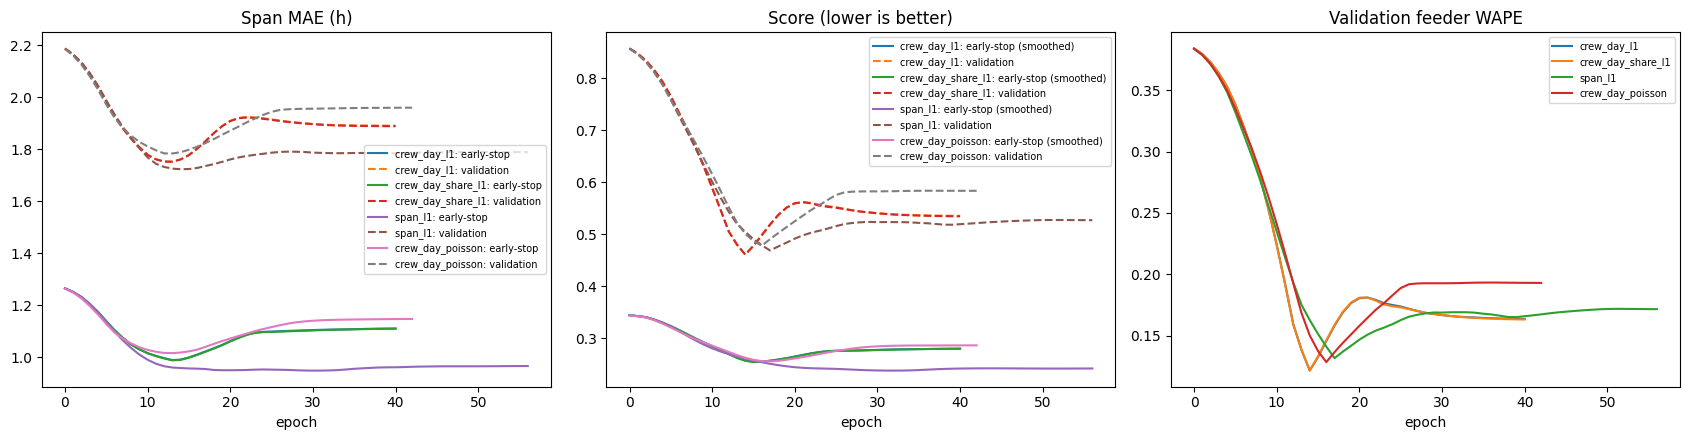

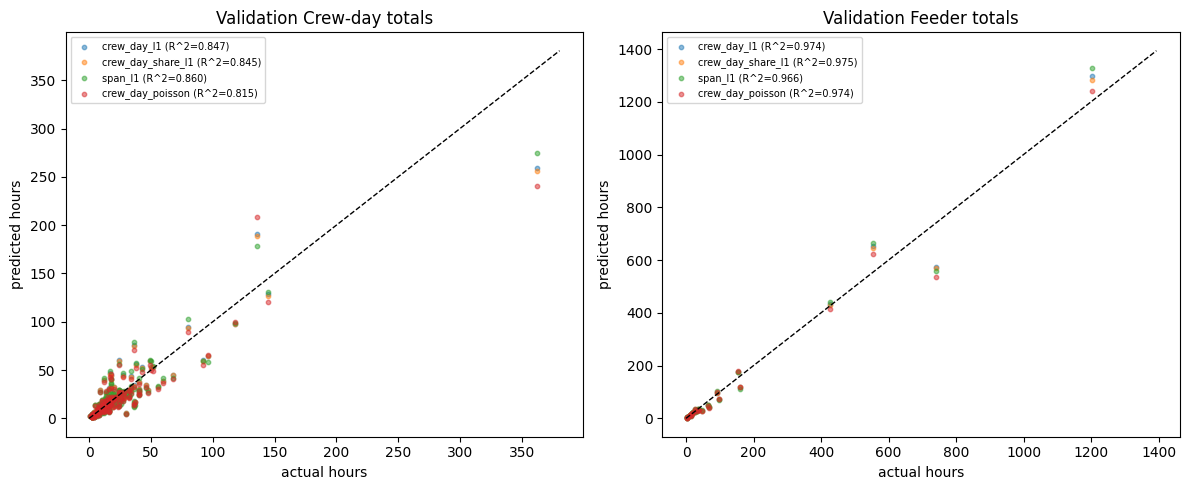

In [19]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
for name, r in RESULTS.items():
    h = r["histories"][0]   # first seed
    axes[0].plot(h["epoch"], h["early_stop_span_mae"], label=f"{name}: early-stop")
    axes[0].plot(h["epoch"], h["validation_span_mae"], "--", label=f"{name}: validation")
    axes[1].plot(h["epoch"], h["score_smoothed"], label=f"{name}: early-stop (smoothed)")
    axes[1].plot(h["epoch"], h["validation_score"], "--", label=f"{name}: validation")
    axes[2].plot(h["epoch"], h["validation_feeder_wape"], label=name)
for ax, title in zip(axes, ["Span MAE (h)", "Score (lower is better)", "Validation feeder WAPE"]):
    ax.set_title(title); ax.set_xlabel("epoch"); ax.legend(fontsize=7)
fig.tight_layout(); fig.savefig(fig_path("crewday_learning_curves.png"), dpi=120)
if SHOW_PLOTS: plt.show()
else: plt.close(fig)

# add R^2 (coefficient of determination) for each prediction
from sklearn.metrics import r2_score
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
base = pd.DataFrame({"y": val["y"].numpy(), "cd": val["cd"], "feeder": val["feeder"]})
for name in RESULTS:
    base[name] = spread[f"pred_{name}"].to_numpy()
for ax, key, title in [(axes[0], "cd", "Crew-day totals"), (axes[1], "feeder", "Feeder totals")]:
    g = base.groupby(key)[["y", *RESULTS.keys()]].sum()
    for name in RESULTS:
        ax.scatter(g["y"], g[name], s=10, alpha=0.5, label=f"{name} (R^2={r2_score(g['y'], g[name]):.3f})")
    lim = float(g.to_numpy().max()) * 1.05
    ax.plot([0, lim], [0, lim], "k--", lw=1)
    ax.set_xlabel("actual hours"); ax.set_ylabel("predicted hours"); ax.set_title(f"Validation {title}")
    ax.legend(fontsize=7)
fig.tight_layout(); fig.savefig(fig_path("crewday_pred_vs_actual.png"), dpi=120)
if USE_TENSORBOARD:
    first = next(iter(RESULTS))
    w = make_writer(f"{RUN_STAMP}_{first}_s{RESULTS[first]['seeds'][0]}")
    w.add_figure("validation/pred_vs_actual", fig, global_step=RESULTS[first]["best_epochs"][0], close=False)
    w.close()
if SHOW_PLOTS: plt.show()
else: plt.close(fig)

In [20]:
UNIT_LEVELS = {"feeder": "feeder"}
if DATA["validation"]["device"] is not None:
    UNIT_LEVELS["device"] = "device"
UNIT_BANDS = {}   # (run, level) -> fitted band and size-bin edges, reused on the holdout


def unit_report(d, pred, level, band=None):
    """Unit totals, WAPE, bias and actual/predicted error band (fitted here unless `band` is given)."""
    u = unit_errors(d["y"].numpy(), pred, d[level])
    u = u[(u["p"] > 0) & (u["y"] > 0)]
    ratio = u["y"] / u["p"]
    if band is None:
        lo, hi = np.quantile(ratio, UNIT_BAND)
        edges = np.quantile(u["n"], [1 / 3, 2 / 3])
        by_size = {}
        for label, mask in (("small", u["n"] <= edges[0]), ("medium", (u["n"] > edges[0]) & (u["n"] <= edges[1])),
                            ("large", u["n"] > edges[1])):
            by_size[label] = (np.quantile(ratio[mask], UNIT_BAND) if mask.sum() >= 5 else (np.nan, np.nan))
        band = {"lo": lo, "hi": hi, "edges": edges, "by_size": by_size}
    inside = (ratio >= band["lo"]) & (ratio <= band["hi"])
    row = {"units": len(u), "median_spans": u["n"].median(),
           "wape": float(np.abs(u["y"] - u["p"]).sum() / u["y"].sum()),
           "total_bias": float(u["p"].sum() / u["y"].sum() - 1),
           "band_lo": band["lo"], "band_hi": band["hi"], "band_width": band["hi"] - band["lo"],
           "coverage": float(inside.mean())}
    for label, (blo, bhi) in band["by_size"].items():
        row[f"width_{label}"] = bhi - blo
    row["size_edges_spans"] = f"<= {band['edges'][0]:.0f} | <= {band['edges'][1]:.0f} | more"
    return row, band


unit_rows = {}
for name in RESULTS:
    pred_val = predict_final(name, DATA["validation"])
    for level in UNIT_LEVELS:
        row, UNIT_BANDS[(name, level)] = unit_report(DATA["validation"], pred_val, level)
        unit_rows[(level, name)] = row
UNIT_TABLE = pd.DataFrame(unit_rows).T
UNIT_TABLE.index.names = ["level", "run"]
vp.show(UNIT_TABLE, "Validation: device vs feeder level", 3)
if "device" not in UNIT_LEVELS:
    print("Device level skipped: set DEVICE_COL to the protective device column.")


Validation: device vs feeder level


units median_spans      wape total_bias   band_lo  \
level  run                                                                   
feeder crew_day_l1          26         12.5  0.142313  -0.016734  0.849481   
       crew_day_share_l1    26         12.5  0.137556  -0.025328  0.851614   
       span_l1              26         12.5  0.165179  -0.010677  0.813832   
       crew_day_poisson     26         12.5  0.135333  -0.054388  0.840348   

                           band_hi band_width  coverage width_small  \
level  run                                                            
feeder crew_day_l1        1.410267   0.560786  0.769231     0.74097   
       crew_day_share_l1  1.410716   0.559102  0.769231    0.734084   
       span_l1            1.471663   0.657831  0.769231    0.996469   
       crew_day_poisson   1.509838    0.66949  0.769231    0.935627   

                         width_medium width_large     size_edges_spans  
level  run                                                              
feeder crew_day_l1           0.492184    0.468609  <= 6 | <= 17 | more  
       crew_day_share_l1     0.499545    0.475905  <= 6 | <= 17 | more  
       span_l1               0.571978    0.527065  <= 6 | <= 17 | more  
       crew_day_poisson      0.579311    0.464892  <= 6 | <= 17 | more

Device level skipped: set DEVICE_COL to the protective device column.


In [ ]:
def feeder_validation_results(name):
    """Per-feeder Validation results for one model: span-summed actual vs predicted hours (overall and split
    accessible / inaccessible), the spread of per-feeder span MAE, and span counts per feeder by veg_tier,
    area_class__area_lcxfm (both from ALL_META) and equipment_types (joined in from span_df)."""
    d = DATA["validation"]
    meta = d["meta"]   # the validation rows of ALL_META, row-aligned with d["y"] / d["feeder"] / predictions
    actual = d["y"].numpy()
    pred = predict_final(name, d)

    span = pd.DataFrame({
        "feeder": d["feeder"],
        "actual": actual,
        "pred": pred,
        "abs_err": np.abs(pred - actual),
        "accessible": meta["inaccessible"].to_numpy() == 0,
        "veg_tier": meta["veg_tier"].to_numpy(),
        "area_class__area_lcxfm": meta["area_class__area_lcxfm"].to_numpy(),
        "equipment_types": meta[SPAN_ID_COL].map(span_equip_lookup).to_numpy(),
    })

    g = span.groupby("feeder")
    table = pd.DataFrame({"n_spans": g.size(), "actual_hours": g["actual"].sum(),
                          "predicted_hours": g["pred"].sum(), "span_mae_avg": g["abs_err"].mean(),
                          "span_mae_max": g["abs_err"].max(), "span_mae_min": g["abs_err"].min()})

    acc = (span[span["accessible"]].groupby("feeder")[["actual", "pred"]].sum()
          .rename(columns={"actual": "actual_hours_accessible", "pred": "predicted_hours_accessible"}))
    inacc = (span[~span["accessible"]].groupby("feeder")[["actual", "pred"]].sum()
            .rename(columns={"actual": "actual_hours_inaccessible", "pred": "predicted_hours_inaccessible"}))
    table = table.join(acc, how="left").join(inacc, how="left")
    hour_cols = ["actual_hours_accessible", "predicted_hours_accessible",
                "actual_hours_inaccessible", "predicted_hours_inaccessible"]
    table[hour_cols] = table[hour_cols].fillna(0.0)

    veg_tier_counts = span.groupby(["feeder", "veg_tier"]).size().unstack(fill_value=0).add_prefix("veg_tier__")
    area_counts = (span.groupby(["feeder", "area_class__area_lcxfm"]).size()
                  .unstack(fill_value=0).add_prefix("area_class__area_lcxfm__"))
    access_counts = (span.groupby(["feeder", "accessible"]).size()
                     .unstack(fill_value=0))
    equip_counts = (span.groupby(["feeder", "equipment_types"]).size()
                   .unstack(fill_value=0).add_prefix("equipment_types__"))
    table = table.join(veg_tier_counts, how="left").join(area_counts, how="left").join(equip_counts, how="left").join(access_counts, how="left")
    return table, span


# span -> equipment_types lookup (span_df's crew-day key is SPAN_ID_COL == "bay_unique", same join key used above)
span_equip_lookup = (span_df.assign(**{SPAN_ID_COL: as_id_text(span_df[SPAN_ID_COL])})
                    .drop_duplicates(SPAN_ID_COL, keep="first").set_index(SPAN_ID_COL)["equipment_types"])

FEEDER_VALIDATION, VALIDATION_SPANS, summary_rows = {}, {}, {}
for name in RESULTS:
    table, span = feeder_validation_results(name)
    FEEDER_VALIDATION[name] = table
    VALIDATION_SPANS[name] = span
    acc, inacc = span["accessible"], ~span["accessible"]
    summary_rows[name] = {
        "actual_hours": span["actual"].sum(), "predicted_hours": span["pred"].sum(),
        "actual_hours_accessible": span.loc[acc, "actual"].sum(),
        "predicted_hours_accessible": span.loc[acc, "pred"].sum(),
        "actual_hours_inaccessible": span.loc[inacc, "actual"].sum(),
        "predicted_hours_inaccessible": span.loc[inacc, "pred"].sum(),
        "r2_accessible": r2_score(span.loc[acc, "actual"], span.loc[acc, "pred"]),
        "r2_inaccessible": r2_score(span.loc[inacc, "actual"], span.loc[inacc, "pred"]),
        "r2_overall": r2_score(span["actual"], span["pred"]),
        "avg_span_mae": table["span_mae_avg"].mean(), "max_span_mae": table["span_mae_avg"].max(),
        "min_span_mae": table["span_mae_avg"].min(),
    }
VALIDATION_SUMMARY = pd.DataFrame(summary_rows).T
vp.show(VALIDATION_SUMMARY, "Validation summary per model: R^2 by accessibility + overall, "
       "feeder span-MAE spread (span_mae_avg across feeders)", 3)
first_name = next(iter(RESULTS))
vp.show(FEEDER_VALIDATION[first_name].head(10), f"Feeder-level Validation detail ({first_name})", 3)



Validation summary per model: R^2 by accessibility + overall, feeder span-MAE spread (span_mae_avg across feeders)


,actual_hours,predicted_hours,actual_hours_accessible,predicted_hours_accessible,actual_hours_inaccessible,predicted_hours_inaccessible,r2_accessible,r2_inaccessible,r2_overall,avg_span_mae,max_span_mae,min_span_mae
crew_day_l1,3879.0,3814.088,1838.5,1896.226,2040.5,1917.862,0.018,0.156,0.341,1.304,4.235,0.094
crew_day_share_l1,3879.0,3780.751,1838.5,1883.974,2040.5,1896.777,0.031,0.154,0.342,1.302,4.289,0.102
span_l1,3879.0,3837.585,1838.5,1907.556,2040.5,1930.029,0.021,0.175,0.352,1.460,4.389,0.220
crew_day_poisson,3879.0,3668.030,1838.5,1882.698,2040.5,1785.332,-0.009,0.139,0.326,1.402,4.751,0.110



Feeder-level Validation detail (crew_day_l1)


,n_spans,actual_hours,predicted_hours,span_mae_avg,span_mae_max,span_mae_min,actual_hours_accessible,predicted_hours_accessible,actual_hours_inaccessible,predicted_hours_inaccessible,veg_tier__Heavy,veg_tier__Light,veg_tier__Medium,area_class__area_lcxfm__Rural,area_class__area_lcxfm__Suburban,area_class__area_lcxfm__Urban,equipment_types__Lift,equipment_types__Manual
feeder,,,,,,,,,,,,,,,,,,
28TH142,16,28.0,32.984001,0.472,1.099,0.000,28.0,32.984001,0.0,0.000000,0,13,3,0,0,16,16,0
28TH243,14,32.0,26.746000,0.744,2.177,0.147,31.0,25.114000,1.0,1.632000,0,9,5,0,0,14,14,0
28TH347,17,37.0,32.502998,0.604,1.600,0.037,33.0,29.114000,4.0,3.389000,0,10,7,0,0,17,17,0
28TH348,11,18.0,20.222000,0.356,0.825,0.021,18.0,20.222000,0.0,0.000000,0,8,3,0,0,11,11,0
A647,6,68.0,44.855000,4.235,8.047,1.005,0.0,0.000000,68.0,44.855000,4,0,2,0,6,0,0,6
C0917,9,35.0,34.150002,1.640,4.775,0.159,35.0,34.150002,0.0,0.000000,3,0,6,0,9,0,9,0
C1317,222,1201.5,1298.197998,2.558,12.364,0.001,210.0,274.609009,991.5,1023.588989,62,13,147,0,214,8,78,144
D7811,68,153.0,175.869003,0.989,4.791,0.024,142.0,168.197006,11.0,7.672000,2,37,29,0,9,59,67,1
E196,180,555.0,652.883972,1.316,5.892,0.018,460.0,517.249023,95.0,135.636002,57,52,69,62,118,0,179,1


## 7 — Save
Saves the crew-day model with everything needed to score new spans: the fitted preparation, the feature list and the
settings. Test and holdout stay untouched; score them in the downstream sections once this approach is chosen.

In [22]:
for name, r in RESULTS.items():
    artifact = os.path.join(NN_DIR, f"nn_{name}_{RUN_STAMP}.pt")
    torch.save({"state_dicts": [m.state_dict() for m in r["models"]],   # v12 change: one per seed, averaged
                "seeds": r["seeds"], "target_mode": r["mode"], "spec": r["spec"],
                "feature_cols": feature_cols, "cat_cardinalities": PREP.cardinalities,
                "crew_days_per_batch": CREW_DAYS_PER_BATCH, "crewday_loss_norm": CREWDAY_LOSS_NORM,
                "span_aux_weight": SPAN_AUX_WEIGHT, "share_loss_weight": SHARE_LOSS_WEIGHT,
                "l1_input_penalty": L1_INPUT_PENALTY, "ema_decay": EMA_DECAY, "split_strategy": SPLIT_USED,
                "naive_span": NAIVE_SPAN, "best_epochs": r["best_epochs"],
                "scale_factor": r["scale"]},   # multiply the seed-averaged output by this
               artifact)
    print(f"Saved: {artifact}")
joblib.dump(PREP, os.path.join(NN_DIR, f"nn_prep_{RUN_STAMP}.joblib"))

Saved: ../deployment/nn/nn_crew_day_l1_20261008-234940.pt
Saved: ../deployment/nn/nn_crew_day_share_l1_20261008-234940.pt
Saved: ../deployment/nn/nn_span_l1_20261008-234940.pt
Saved: ../deployment/nn/nn_crew_day_poisson_20261008-234940.pt


['../deployment/nn/nn_prep_20261008-234940.joblib']

## 8 — Final holdout (one time only)
Runs only when `READY_FOR_FINAL_HOLDOUT = True`. 

In [23]:
HOLDOUT_RUN = next(iter(RESULTS))   # set to the run chosen on Validation BEFORE flipping the flag

if READY_FOR_FINAL_HOLDOUT:
    DATA["holdout"] = build_split(FULL_X["holdout"], FULL_Y["holdout"], FULL_META["holdout"],
                                  eval_positions("holdout"))
    hold = DATA["holdout"]
    hold_scores = pd.DataFrame({name: score(hold, predict_final(name, hold)) for name in RESULTS}).T
    hold_scores.index.name = "run"
    vp.show(hold_scores, f"Final holdout (chosen run: {HOLDOUT_RUN})", 4)

    # v12 change: feeders the model never trained on (new since the cut-off) scored separately
    unseen = ~hold["meta"]["feeder_seen_before"].to_numpy()
    if unseen.sum() >= 30:
        sub = {k: (v[unseen] if isinstance(v, np.ndarray) else v) for k, v in hold.items() if k not in ("meta",)}
        sub["y"], sub["x_num"], sub["x_cat"] = hold["y"][unseen], hold["x_num"][unseen], hold["x_cat"][unseen]
        sub["cd"] = pd.factorize(hold["cd"][unseen])[0]
        vp.show(pd.DataFrame({name: score(sub, predict_final(name, sub)) for name in RESULTS}).T,
                f"Holdout, feeders not seen before the cut-off ({unseen.sum():,} spans)", 4)
    else:
        print(f"Only {unseen.sum()} holdout spans are on feeders new since the cut-off - too few to score separately.")

    # v12 change: device / feeder bands fitted on Validation, coverage checked here
    hold_units = {}
    for name in RESULTS:
        p = predict_final(name, hold)
        for level in UNIT_LEVELS:
            hold_units[(level, name)], _ = unit_report(hold, p, level, band=UNIT_BANDS[(name, level)])
    vp.show(pd.DataFrame(hold_units).T, "Holdout: device vs feeder level (bands from Validation)", 3)

    span_out = hold["meta"][[SPAN_ID_COL, FEEDER_COL, CREW_DAY_COL, "crew_day_known", "feeder_seen_before"]].copy()
    span_out["actual_hours"] = hold["y"].numpy()
    for name in RESULTS:
        span_out[f"pred_{name}"] = predict_final(name, hold)
    span_out.to_csv(os.path.join(NN_DIR, f"holdout_span_predictions_{RUN_STAMP}.csv"), index=False)
    print(f"Span-level holdout predictions saved for {len(span_out):,} spans.")
else:
    print("Holdout gate is closed (READY_FOR_FINAL_HOLDOUT = False). Nothing was scored.")

Holdout gate is closed (READY_FOR_FINAL_HOLDOUT = False). Nothing was scored.
